# 04c - Classificação: risco de *default* na concessão

Prever, no momento da concessão (T4), se um empréstimo de 36 meses acaba em **Default** ou em **Good standing**. Nesse momento já se conhecem a taxa de juro, o grau e a prestação, por isso entram como inputs (ao contrário da regressão).

Todos os modelos passam pelo mesmo `CrossValidationRunner` (`src/lending/experiment.py`), com os mesmos 3 folds anuais e o mesmo pré-processamento. Os modelos e as grelhas estão em `src/lending/model_catalog.py`.

| Requisito do enunciado | Onde |
|---|---|
| *"Use the same eligible evaluation cohort and split definitions for all models within a task"* | Secção 1: a coorte e os folds são os mesmos para todos os modelos |
| *"Prepare one comparison table for each task, including baselines"* | Secção 2: as baselines são as primeiras linhas da tabela |
| *"Classification: confusion matrix, precision, recall, F1 (macro and micro averages), AUC, and accuracy"* | Métricas calculadas pelo runner (`src/lending/evaluation.py`) |
| *"Present the mean and the variation of the metric in the cross-validation procedures"* | `comparison_table()`: média ± desvio-padrão nos 3 folds |
| *"Report training sample sizes, tuning procedures, and any computational limitations"* | Colunas `n_train` e `fit_seconds`; a grelha de cada modelo |

**Antes de correr:** `01_preprocessamento.ipynb` (gera `classificacao_treino.pkl`).

**Ficheiros:** os resultados vão para `reports/results/classification_cv.csv` (entra no Git) e as previsões fora do fold para `data/processed/oof/classification/` (fora do Git). O runner retoma onde parou: as combinações (modelo, configuração, fold) que já estão no CSV não voltam a correr.

In [1]:
# Setup: imports e caminhos do projeto
import json
import sys
from pathlib import Path

# Importar o pacote do projeto.
try:
    import lending
except ModuleNotFoundError:
    for parent in [Path.cwd(), *Path.cwd().parents]:
        if (parent / "src" / "lending").is_dir():
            sys.path.insert(0, str(parent / "src"))
            break
    import lending

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import roc_auc_score

from lending import config
from lending.baselines import GradeRateBaseline
from lending.evaluation import (best_threshold, classification_metrics, confusion_table, format_mean_std,
                                labels_from_proba, paired_bootstrap_diff, positive_proba)
from lending.experiment import ColumnDropper, CrossValidationRunner
from lending.knn import KNNClassifier
from lending.model_catalog import COLLINEAR_DROP, KNN_K, classification_specs
from lending.plot_style import CATEGORICAL, SEQUENTIAL_CMAP, apply_style
from lending.storage import PickleStore

apply_style()
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 30)

## 1. Coorte e folds

**Coorte.** São os 31 522 empréstimos de 36 meses concedidos entre 2007-06 e 2011-12. Todos acabaram o prazo antes do corte de observação (31/12/2018), por isso o desfecho de cada um já é conhecido. Os empréstimos de 2012 a 2014 ficam de fora (embargo): na data de treino simulada (01/01/2015) ainda não tinham terminado.

**Alvo binário.** A classe *At risk* tem 0 casos no treino (só aparece em empréstimos ainda ativos), por isso a classificação é *Good standing* contra *Default*. No teste de 2015, os *At risk* contam como *Default*.

**Folds: janela expansível anual.** Cada fold treina com todos os anos anteriores e valida no ano seguinte. Nunca se treina com empréstimos posteriores aos da validação, ao contrário do que aconteceria numa validação cruzada com folds aleatórios, que deixaria o modelo aprender com o futuro.

O runner ordena sempre as linhas por `issue_d` antes de criar os folds. É disso que depende a paragem antecipada da MLP e do LightGBM, que usa os 15% mais recentes do treino de cada fold.

In [2]:
data = PickleStore.load(config.CLS_TRAIN_PKL, expected_type=pd.DataFrame)
print(f"{len(data):,} empréstimos, {data.shape[1]} colunas")

counts = data[config.CLASS_COL].value_counts().reindex(config.CLASS_ORDER)
pd.DataFrame({"empréstimos": counts, "%": (100 * counts / counts.sum()).round(1)})

31,522 empréstimos, 152 colunas


,empréstimos,%
target,,
Good standing,27646,87.7
Default,3876,12.3


Tabela dos folds, com a taxa de *default* de cada lado e o peso que os modelos dão a um *Default* quando usam `class_weight="balanced"`.

O peso "balanced" de uma classe é $w_c = \dfrac{n}{2\, n_c}$ ($n$ linhas de treino, $n_c$ da classe $c$). Com 12% de *Default*, cada *Default* pesa cerca de 4 e cada *Good standing* cerca de 0,6. Assim, as duas classes contam o mesmo na função de perda, sem duplicar nem apagar linhas (não há reamostragem).

In [3]:
runner = CrossValidationRunner("classification")
folds = runner.folds(data)

# Taxa de default e peso "balanced" de cada fold (os folds usam os dados ordenados por issue_d)
ordered = runner.prepare(data)
is_default = ordered[config.CLASS_COL].eq("Default")
extra = []
for fold, (tr, va) in enumerate(runner.splitter.split(ordered["issue_d"]), start=1):
    rate = is_default.iloc[tr].mean()
    extra.append({"fold": fold,
                  "default no treino (%)": round(100 * rate, 1),
                  "default na validação (%)": round(100 * is_default.iloc[va].mean(), 1),
                  "peso de Default": round(1 / (2 * rate), 2),
                  "peso de Good standing": round(1 / (2 * (1 - rate)), 2)})
folds.join(pd.DataFrame(extra).set_index("fold"))

,treino,validação,linhas treino,linhas validação,default no treino (%),default na validação (%),peso de Default,peso de Good standing
fold,,,,,,,,
1,2007 a 2008,2009,2991,5280,21.9,13.7,2.29,0.64
2,2007 a 2009,2010,8271,9153,16.6,10.9,3.00,0.60
3,2007 a 2010,2011,17424,14098,13.6,10.6,3.67,0.58


**Leitura.**

- **Desequilíbrio:** 12,3% de *Default*, cerca de 1 para 7. Um modelo que nunca prevê *Default* acerta em 88% dos casos, por isso a *accuracy* sozinha não serve para escolher modelos.
- **Mudança temporal:** a taxa de *default* desce de 21,9% no treino do fold 1 (2007–2008, os anos da crise financeira) para 13,6% no do fold 3. As validações ficam entre 10,6% e 13,7%. O treino de cada fold tem sempre mais *default* do que o ano que se segue, por isso um modelo treinado nos anos maus tende a sobrestimar o risco do ano seguinte.
- **Fold 1 pequeno:** treina com 2 991 empréstimos, menos de um quinto do fold 3. É de esperar mais variação entre folds nos modelos mais flexíveis (MLP, LightGBM), e isso deve ser reportado.
- **Pesos:** o peso de *Default* sobe de 2,3 para 3,7 porque a proporção de *Default* no treino desce.

## 2. Baselines

As baselines são a linha de referência da tabela de comparação (critérios de sucesso em `docs/01_formulacao_problema/definicao_tarefas.md`):

- **Classe maioritária** (`DummyClassifier(strategy="most_frequent")`): prevê sempre *Good standing*. A probabilidade de *Default* é 0 para todos, por isso a AUC é 0,5. Mostra porque é que a *accuracy* engana com classes desequilibradas: acerta em cerca de 88% dos casos sem identificar um único *Default*.
- **Taxa do grau** (`GradeRateBaseline`): a probabilidade de *Default* é a taxa de *default* do grau (A a G) no treino do fold. Representa a avaliação de risco da própria LendingClub. Um modelo só acrescenta valor se fizer melhor do que o grau.

As duas leem colunas originais (`grade`), por isso não passam pelo pré-processamento (`preprocess=False`).

**Limiar.** No CSV, as métricas que dependem do limiar usam 0,5. Na tabela de comparação, o runner escolhe para cada configuração o limiar (de 0,05 a 0,95) que maximiza o F1 macro nas previsões fora do fold dos 3 folds juntos, e recalcula as métricas de cada fold com esse limiar. A AUC não depende do limiar.

In [4]:
specs = {spec.name: spec for spec in classification_specs()}
BASELINES = ["Classe maioritária", "Taxa do grau"]
runner.run(data, [specs[name] for name in BASELINES]);

In [5]:
# Taxa de default de cada grau no treino do último fold (2007-2010): é o que a baseline prevê
tr, va = list(runner.splitter.split(ordered["issue_d"]))[-1]
grade_model = GradeRateBaseline().fit(ordered.iloc[tr][runner.columns], ordered[config.CLASS_COL].iloc[tr])
grades = ordered.iloc[tr]["grade"].value_counts().sort_index()
pd.DataFrame({"empréstimos": grades, "default (%)": (100 * grade_model.rates_).round(1)})

,empréstimos,default (%)
A,4166,5.2
B,4940,11.4
C,4136,15.5
D,2586,20.2
E,1027,23.3
F,359,32.9
G,210,35.7


In [6]:
# Resultados por fold, com o limiar de 0,5 (uma linha do CSV por modelo e fold)
cols = ["model", "fold", "valid_period", "n_train", "n_valid", "f1_macro", "f1_micro",
        "accuracy", "recall_default", "auc"]
runner.results().query("model in @BASELINES")[cols].round(3)

,model,fold,valid_period,n_train,n_valid,f1_macro,f1_micro,accuracy,recall_default,auc
0,Classe maioritária,1,2009,2991,5280,0.463,0.863,0.863,0.0,0.500
1,Taxa do grau,1,2009,2991,5280,0.463,0.863,0.863,0.0,0.616
2,Classe maioritária,2,2010,8271,9153,0.471,0.891,0.891,0.0,0.500
3,Taxa do grau,2,2010,8271,9153,0.471,0.891,0.891,0.0,0.654
4,Classe maioritária,3,2011,17424,14098,0.472,0.894,0.894,0.0,0.500
5,Taxa do grau,3,2011,17424,14098,0.472,0.894,0.894,0.0,0.622


In [7]:
# Tabela de comparação: média ± desvio-padrão nos 3 folds, com o limiar escolhido
runner.comparison_table()

,params,n_train,threshold,f1_macro,f1_micro,precision_macro,precision_micro,recall_macro,recall_micro,accuracy,recall_default,auc,fit_seconds
model,,,,,,,,,,,,,
MLP,"{""hidden_layers"": [256, 128, 64], ""learning_ra...",9562,0.56,0.573 ± 0.008,0.819 ± 0.023,0.571 ± 0.007,0.819 ± 0.023,0.575 ± 0.009,0.819 ± 0.023,0.819 ± 0.023,0.257 ± 0.005,0.666 ± 0.025,3.7
Regressão logística,"{""C"": 0.1}",9562,0.56,0.570 ± 0.010,0.814 ± 0.028,0.567 ± 0.009,0.814 ± 0.028,0.573 ± 0.012,0.814 ± 0.028,0.814 ± 0.028,0.259 ± 0.020,0.669 ± 0.021,0.1
Random Forest,"{""max_features"": 0.3, ""min_samples_leaf"": 50}",9562,0.52,0.564 ± 0.021,0.796 ± 0.067,0.564 ± 0.019,0.796 ± 0.067,0.573 ± 0.014,0.796 ± 0.067,0.796 ± 0.067,0.283 ± 0.073,0.662 ± 0.036,1.0
LightGBM,"{""learning_rate"": 0.1, ""num_leaves"": 63}",9562,0.52,0.561 ± 0.008,0.801 ± 0.051,0.560 ± 0.009,0.801 ± 0.051,0.568 ± 0.004,0.801 ± 0.051,0.801 ± 0.051,0.265 ± 0.059,0.644 ± 0.031,0.4
kNN,"{""n_neighbors"": 101, ""weights"": ""distance""}",9562,0.52,0.555 ± 0.011,0.792 ± 0.026,0.551 ± 0.009,0.792 ± 0.026,0.564 ± 0.013,0.792 ± 0.026,0.792 ± 0.026,0.266 ± 0.010,0.642 ± 0.028,0.0
Árvore,"{""max_depth"": 6, ""min_samples_leaf"": 50}",9562,0.62,0.541 ± 0.011,0.816 ± 0.051,0.546 ± 0.004,0.816 ± 0.051,0.542 ± 0.018,0.816 ± 0.051,0.816 ± 0.051,0.187 ± 0.094,0.613 ± 0.007,0.1
Taxa do grau,{},9562,0.21,0.513 ± 0.045,0.733 ± 0.174,0.550 ± 0.009,0.733 ± 0.174,0.561 ± 0.041,0.733 ± 0.174,0.733 ± 0.174,0.344 ± 0.298,0.630 ± 0.020,0.0
Classe maioritária,{},9562,0.05,0.469 ± 0.005,0.882 ± 0.017,0.441 ± 0.008,0.882 ± 0.017,0.500 ± 0.000,0.882 ± 0.017,0.882 ± 0.017,0.000 ± 0.000,0.500 ± 0.000,0.0


In [8]:
def per_fold(model, cid=None):
    """
    Métricas de cada fold com o limiar escolhido na validação cruzada (o mesmo nos 3 folds)

    Lê as previsões fora do fold guardadas pelo runner; não treina nada.

    Parameters:
        model (str): Nome do modelo no catálogo
        cid (str | None): Configuração; por omissão, a melhor do modelo (F1 macro médio)
    """
    if cid is None:
        cid = runner.best().set_index("model").loc[model, "config_id"]
    threshold = runner.threshold(model, cid)
    rows = []
    for fold, part in runner.oof(model, cid).groupby("fold"):
        metrics = classification_metrics(part["y_true"], part["p_default"], threshold)
        rows.append({"fold": fold, "limiar": threshold,
                     "previstos Default (%)": round(100 * (part["p_default"] >= threshold).mean(), 1),
                     **{m: round(metrics[m], 3) for m in ["f1_macro", "accuracy", "recall_default", "auc"]}})
    return pd.DataFrame(rows).set_index("fold")


# Taxa do grau, fold a fold, com o limiar escolhido
per_fold("Taxa do grau")

,limiar,previstos Default (%),f1_macro,accuracy,recall_default,auc
fold,,,,,,
1,0.21,49.9,0.471,0.541,0.645,0.616
2,0.21,18.7,0.559,0.778,0.338,0.654
3,0.21,2.4,0.508,0.880,0.049,0.622


**Leitura.**

- **Classe maioritária:** *accuracy* de 0,88, mas recall de *Default* 0 e F1 macro 0,47. É a armadilha das classes desequilibradas: a *accuracy* é alta e o modelo não serve para nada.
- **O grau ordena bem o risco:** a taxa de *default* sobe sempre de A (5,2%) para G (35,7%). Daí a AUC de 0,63 ± 0,02 da baseline.
- **Com o limiar de 0,5, a taxa do grau é igual à classe maioritária:** nenhum grau chega a 50% de *default*, por isso prevê sempre *Good standing*. As métricas que dependem do limiar ficam iguais às da classe maioritária e só a AUC as distingue. É por isso que o limiar se escolhe e não se fixa em 0,5.
- **Com o limiar escolhido (0,21):** o F1 macro sobe para 0,51 ± 0,05, mas o recall de *Default* varia muito, 0,34 ± 0,30. A tabela por fold mostra porquê:
    - no fold 1, o treino é de 2007–2008 e as taxas de cada grau são altas (C já tem 21,7%). Os graus C a G passam o limiar e metade dos empréstimos de 2009 são marcados como *Default*;
    - no fold 3, as taxas já desceram (C tem 15,5%) e só F e G passam o limiar: 2,4% dos empréstimos são marcados.
- **Conclusão para o resto do bloco:** a ordenação do risco (AUC) é estável de ano para ano (0,62 a 0,65), mas o nível das probabilidades muda com o tempo. Um limiar fixo dá decisões muito diferentes de um ano para o outro, e isso vai pesar no teste de 2015. Por isso, a AUC é a medida mais estável e o F1 macro tem de ser lido com o desvio-padrão ao lado.
- **A fasquia:** para acrescentar alguma coisa à avaliação da própria LendingClub, um modelo tem de passar a AUC de 0,63 e o F1 macro de 0,51 da taxa do grau.
- Em classificação binária, o F1, a precisão e o recall *micro* são iguais à *accuracy* (cada erro é ao mesmo tempo um falso positivo de uma classe e um falso negativo da outra). Não é um erro de cálculo.
- O limiar é escolhido nas mesmas previsões fora do fold em que se mede o F1, por isso o F1 da validação cruzada fica ligeiramente otimista. O limiar nunca é mudado com o teste.

## 3. Modelos do scikit-learn que não são ensembles

O enunciado pede pelo menos dois modelos supervisionados do scikit-learn que não sejam ensembles. Na classificação são a regressão logística e a árvore de decisão. Os dois passam pelo pré-processamento da Parte 1 (imputação, *clipping*, padronização e *one-hot*), ajustado só no treino de cada fold.

**Regressão logística com penalização L2.** Modela o *log-odds* do *Default* como uma soma ponderada das features:

$$\log \frac{p}{1-p} = \beta_0 + \beta_1 x_1 + \dots + \beta_m x_m, \qquad p = \frac{1}{1 + e^{-(\beta_0 + \beta \cdot x)}}$$

- Os coeficientes minimizam a *log-loss* mais uma penalização $\tfrac{1}{2}\lVert\beta\rVert^2$. O `C` é o inverso da força da penalização: com `C` pequeno, os coeficientes são puxados para 0 (modelo mais simples); com `C` grande, quase não há penalização. A grelha tem `C` de $10^{-3}$ a $10^{2}$.
- A penalização L2 estabiliza os coeficientes quando há colunas correlacionadas (FICO *low*/*high*, as colunas do *one-hot*). Como o pipeline padroniza as colunas, a penalização trata todas por igual.
- Sai o `dti_with_loan`, que é exatamente `dti + installment_to_income`. Com uma combinação linear exata, há infinitos conjuntos de coeficientes que dão as mesmas previsões, e os *odds ratios* dessas colunas deixariam de ter leitura.
- `class_weight="balanced"`: a perda de cada *Default* conta cerca de 4 vezes. O modelo passa a comportar-se como se as duas classes tivessem a mesma frequência, por isso as probabilidades deixam de estimar a probabilidade real de *Default* e ficam deslocadas para cima. A AUC (ordenação) quase não muda, mas o limiar tem de ser escolhido.

**Árvore de decisão.** Divide os dados, passo a passo, com perguntas do tipo "feature ≤ valor". Em cada nó escolhe a pergunta que mais reduz a impureza de Gini. Cada folha dá a proporção (ponderada) de *Default* dos empréstimos de treino que lá caem.

- Sem limites, a árvore cresce até decorar o treino (sobreajustamento). A grelha controla isso com `max_depth` {4, 6, 8, 12}, o número máximo de perguntas seguidas, e `min_samples_leaf` {50, 200}, o mínimo de empréstimos por folha.
- Não precisa de padronização nem de relações lineares e capta interações (ex.: FICO baixo e taxa alta ao mesmo tempo). Por isso mantém o `dti_with_loan`.
- As probabilidades só têm tantos valores diferentes quantas as folhas, o que limita a ordenação fina (AUC).

In [9]:
LINEAR_TREE = ["Regressão logística", "Árvore"]
runner.run(data, [specs[name] for name in LINEAR_TREE]);

In [10]:
def grid_table(model):
    """ Uma linha por configuração da grelha: parâmetros, limiar escolhido e média/desvio nos 3 folds. """
    summary = runner.summary().query("model == @model")
    # o json devolve listas (ex.: as camadas da MLP); em tuplo já se podem ordenar
    params = pd.DataFrame([{key: tuple(value) if isinstance(value, list) else value
                            for key, value in json.loads(text).items()} for text in summary["params"]],
                          index=summary.index)
    cols = ["threshold", "f1_macro_mean", "f1_macro_std", "auc_mean", "auc_std",
            "recall_default_mean", "fit_seconds"]
    return (pd.concat([params, summary[cols].round(3)], axis=1)
            .sort_values(list(params.columns)).reset_index(drop=True))


grid_table("Regressão logística")

,C,threshold,f1_macro_mean,f1_macro_std,auc_mean,auc_std,recall_default_mean,fit_seconds
0,0.001,0.54,0.567,0.006,0.664,0.026,0.270,0.059
1,0.010,0.53,0.569,0.007,0.671,0.023,0.322,0.080
2,0.100,0.56,0.570,0.010,0.669,0.021,0.259,0.110
3,1.000,0.54,0.569,0.007,0.664,0.021,0.284,0.152
4,10.000,0.54,0.569,0.006,0.661,0.021,0.269,0.169
5,100.000,0.54,0.569,0.006,0.661,0.021,0.271,0.204


In [11]:
grid_table("Árvore")

,max_depth,min_samples_leaf,threshold,f1_macro_mean,f1_macro_std,auc_mean,auc_std,recall_default_mean,fit_seconds
0,4,50,0.52,0.538,0.013,0.625,0.018,0.194,0.105
1,4,200,0.52,0.529,0.016,0.623,0.020,0.236,0.100
2,6,50,0.62,0.541,0.011,0.613,0.007,0.187,0.121
3,6,200,0.58,0.529,0.016,0.624,0.013,0.200,0.115
4,8,50,0.66,0.540,0.007,0.603,0.011,0.176,0.156
5,8,200,0.58,0.541,0.023,0.623,0.014,0.288,0.130
6,12,50,0.68,0.535,0.004,0.589,0.010,0.186,0.164
7,12,200,0.58,0.541,0.023,0.623,0.012,0.284,0.147


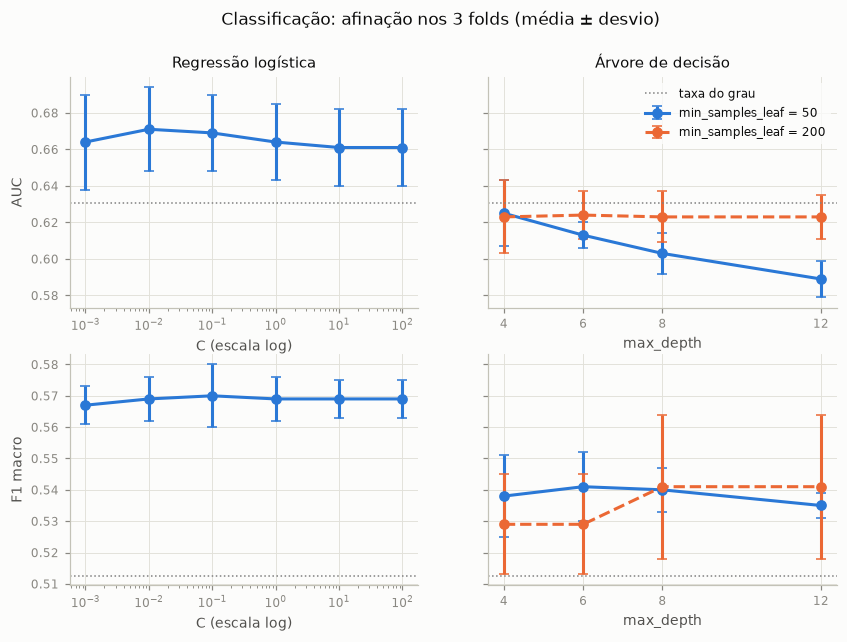

In [12]:
# Afinação: AUC e F1 macro (média ± desvio nos 3 folds) em função dos hiperparâmetros
baseline = runner.summary().set_index("model").loc["Taxa do grau"]
logit, tree = grid_table("Regressão logística"), grid_table("Árvore")

fig, axes = plt.subplots(2, 2, figsize=(9, 6), sharey="row")
for row, metric, label in [(0, "auc", "AUC"), (1, "f1_macro", "F1 macro")]:
    ax = axes[row, 0]
    ax.errorbar(logit["C"], logit[f"{metric}_mean"], yerr=logit[f"{metric}_std"], marker="o", capsize=3)
    ax.set(xscale="log", xlabel="C (escala log)", ylabel=label)
    ax = axes[row, 1]
    for leaf, style in zip([50, 200], ["-", "--"]):
        part = tree[tree["min_samples_leaf"] == leaf]
        ax.errorbar(part["max_depth"], part[f"{metric}_mean"], yerr=part[f"{metric}_std"],
                    marker="o", capsize=3, linestyle=style, label=f"min_samples_leaf = {leaf}")
    ax.set(xlabel="max_depth", xticks=[4, 6, 8, 12])
    for ax in axes[row]:
        ax.axhline(baseline[f"{metric}_mean"], color="0.5", linewidth=1, linestyle=":", label="taxa do grau")
axes[0, 0].set_title("Regressão logística")
axes[0, 1].set_title("Árvore de decisão")
axes[0, 1].legend()
fig.suptitle("Classificação: afinação nos 3 folds (média ± desvio)")
fig.savefig(config.FIGURES_DIR / "mod_cls_logistica_arvore.png")
plt.show()

In [13]:
# Melhor configuração de cada um, fold a fold, com o limiar escolhido
pd.concat({name: per_fold(name) for name in LINEAR_TREE})

limiar  previstos Default (%)  f1_macro  accuracy  \
                    fold                                                      
Regressão logística 1       0.56                   15.2     0.559     0.782   
                    2       0.56                   12.8     0.579     0.824   
                    3       0.56                   10.9     0.572     0.835   
Árvore              1       0.62                   18.5     0.553     0.758   
                    2       0.62                    8.4     0.541     0.840   
                    3       0.62                    6.8     0.530     0.851   

                          recall_default    auc  
                    fold                         
Regressão logística 1              0.259  0.645  
                    2              0.280  0.685  
                    3              0.239  0.676  
Árvore              1              0.293  0.610  
                    2              0.150  0.607  
                    3              0.117  0.621

In [14]:
# Tabela de comparação até aqui
runner.comparison_table()

,params,n_train,threshold,f1_macro,f1_micro,precision_macro,precision_micro,recall_macro,recall_micro,accuracy,recall_default,auc,fit_seconds
model,,,,,,,,,,,,,
MLP,"{""hidden_layers"": [256, 128, 64], ""learning_ra...",9562,0.56,0.573 ± 0.008,0.819 ± 0.023,0.571 ± 0.007,0.819 ± 0.023,0.575 ± 0.009,0.819 ± 0.023,0.819 ± 0.023,0.257 ± 0.005,0.666 ± 0.025,3.7
Regressão logística,"{""C"": 0.1}",9562,0.56,0.570 ± 0.010,0.814 ± 0.028,0.567 ± 0.009,0.814 ± 0.028,0.573 ± 0.012,0.814 ± 0.028,0.814 ± 0.028,0.259 ± 0.020,0.669 ± 0.021,0.1
Random Forest,"{""max_features"": 0.3, ""min_samples_leaf"": 50}",9562,0.52,0.564 ± 0.021,0.796 ± 0.067,0.564 ± 0.019,0.796 ± 0.067,0.573 ± 0.014,0.796 ± 0.067,0.796 ± 0.067,0.283 ± 0.073,0.662 ± 0.036,1.0
LightGBM,"{""learning_rate"": 0.1, ""num_leaves"": 63}",9562,0.52,0.561 ± 0.008,0.801 ± 0.051,0.560 ± 0.009,0.801 ± 0.051,0.568 ± 0.004,0.801 ± 0.051,0.801 ± 0.051,0.265 ± 0.059,0.644 ± 0.031,0.4
kNN,"{""n_neighbors"": 101, ""weights"": ""distance""}",9562,0.52,0.555 ± 0.011,0.792 ± 0.026,0.551 ± 0.009,0.792 ± 0.026,0.564 ± 0.013,0.792 ± 0.026,0.792 ± 0.026,0.266 ± 0.010,0.642 ± 0.028,0.0
Árvore,"{""max_depth"": 6, ""min_samples_leaf"": 50}",9562,0.62,0.541 ± 0.011,0.816 ± 0.051,0.546 ± 0.004,0.816 ± 0.051,0.542 ± 0.018,0.816 ± 0.051,0.816 ± 0.051,0.187 ± 0.094,0.613 ± 0.007,0.1
Taxa do grau,{},9562,0.21,0.513 ± 0.045,0.733 ± 0.174,0.550 ± 0.009,0.733 ± 0.174,0.561 ± 0.041,0.733 ± 0.174,0.733 ± 0.174,0.344 ± 0.298,0.630 ± 0.020,0.0
Classe maioritária,{},9562,0.05,0.469 ± 0.005,0.882 ± 0.017,0.441 ± 0.008,0.882 ± 0.017,0.500 ± 0.000,0.882 ± 0.017,0.882 ± 0.017,0.000 ± 0.000,0.500 ± 0.000,0.0


**Leitura.**

*Regressão logística*

- **O `C` quase não importa:** o F1 macro fica entre 0,567 e 0,570 e a AUC entre 0,661 e 0,671 em toda a grelha. As diferenças são menores do que a variação entre folds (desvio de 0,02 na AUC). Mesmo o fold 1 tem cerca de 25 empréstimos por coeficiente, e com as colunas padronizadas a penalização muda pouco. O runner escolhe `C = 0,1` (o melhor F1 macro); `C = 0,01` tem a melhor AUC, mas a diferença não é real.
- **Passa a baseline do grau:** AUC 0,669 ± 0,021 contra 0,630 ± 0,020, e F1 macro 0,570 ± 0,010 contra 0,513 ± 0,045. Com as mesmas informações (grau, taxa, FICO, DTI, etc.), um modelo linear ordena o risco melhor do que o grau sozinho.
- **O limiar fica perto de 0,5 e é estável no tempo.** Com `class_weight="balanced"`, o treino de cada fold pesa como se tivesse 50% de cada classe, qualquer que seja a taxa de *default* real desses anos. As probabilidades deixam de acompanhar a taxa de *default* do treino, que era o problema da baseline do grau. Com o limiar de 0,56, a percentagem de empréstimos marcados como *Default* fica entre 10,9% e 15,2% nos três folds (na taxa do grau ia de 50% a 2,4%), e o recall de *Default* entre 0,24 e 0,28.
- **O recall de *Default* é baixo (0,26):** o modelo apanha cerca de um quarto dos *Default*. O F1 macro dá o mesmo peso aos erros nas duas classes; para apanhar mais *Default* seria preciso marcar muitos mais *Good standing*. Num credor, um *Default* não detetado custa mais do que um bom empréstimo recusado, e o limiar escolhia-se pelo custo. Isso fica para o plano de *deployment*.
- A *accuracy* (0,81) é mais baixa do que a da classe maioritária (0,88), como esperado: marcar 11–15% dos empréstimos como *Default* gera erros nos *Good standing*.

*Árvore de decisão*

- **Uma árvore sozinha não ordena o risco melhor do que o grau.** O F1 macro (0,529–0,541) passa o da baseline, mas a AUC (0,589–0,625) fica sempre abaixo dos 0,630 da taxa do grau.
- **Sobreajustamento:** com folhas de 50 empréstimos, a AUC desce de 0,625 para 0,589 quando a profundidade passa de 4 para 12. As folhas pequenas têm proporções de *default* com muito ruído. Com folhas de 200, a profundidade quase não muda nada, porque é o mínimo por folha que trava o crescimento: no fold 1 (2 991 empréstimos) cabem no máximo 14 folhas, e nesse fold as profundidades 6, 8 e 12 dão a mesma árvore.
- **A escolha é instável:** a melhor configuração pelo F1 macro, `max_depth = 6` e `min_samples_leaf = 50`, tem uma AUC (0,613) pior do que as das folhas de 200. As diferenças de F1 macro entre configurações (0,529 a 0,541) cabem no desvio entre folds. A árvore também é menos estável no tempo: a percentagem marcada desce de 18,5% para 6,8% e o recall de *Default* de 0,29 para 0,12.
- Esta variância de uma árvore isolada é a razão de ser dos *ensembles*: a *Random Forest* faz a média de muitas árvores, cada uma treinada numa amostra diferente (próximo passo).

**Custo:** cada ajuste leva menos de 0,3 s, por isso a grelha completa dos dois modelos corre em cerca de 10 s.

## 4. Ensembles: Random Forest (bagging) e LightGBM (boosting)

O enunciado pede um *ensemble* de *bagging* e um de *boosting* em cada tarefa. Os dois combinam muitas árvores de decisão, mas de maneiras opostas:

| | *Bagging* (Random Forest) | *Boosting* (LightGBM) |
|---|---|---|
| Como treina as árvores | Em paralelo, cada uma numa amostra diferente | Em sequência, cada uma corrige os erros das anteriores |
| Que árvores | Grandes: pouco enviesadas, com muita variância | Pequenas: muito enviesadas, com pouca variância |
| O que reduz | A variância (a média de árvores diferentes) | O enviesamento (a soma de muitas correções pequenas) |
| Sobreajustamento | Mais árvores não sobreajustam, só estabilizam a média | Árvores a mais sobreajustam; é preciso parar a tempo |

**Random Forest.** 300 árvores sem limite de profundidade.

- Cada árvore treina numa amostra *bootstrap* (com reposição) de 30% das linhas (`max_samples=0.3`).
- Em cada divisão, só pode escolher entre algumas colunas sorteadas (`max_features`). Depois do pré-processamento há 117 a 123 colunas, por isso `"sqrt"` dá cerca de 11 colunas por divisão e `0.3` cerca de 36.
- Estas duas fontes de acaso tornam as árvores diferentes umas das outras. Os erros de árvores pouco correlacionadas anulam-se na média, e a variância baixa sem aumentar o enviesamento.
- A probabilidade prevista é a média, nas 300 árvores, da proporção (ponderada) de *Default* na folha onde o empréstimo cai.
- Grelha: `max_features` {"sqrt", 0.3} × `min_samples_leaf` {10, 50}. Sem limite de profundidade, é o mínimo por folha que trava o crescimento.
- `class_weight="balanced_subsample"`: os pesos *balanced* calculados em cada amostra *bootstrap*.

**LightGBM.** *Gradient boosting*. Começa numa previsão constante e acrescenta árvores uma a uma. Cada nova árvore aproxima o gradiente da *log-loss* do *ensemble* atual (na prática, os erros que ainda faltam corrigir) e entra multiplicada pela taxa de aprendizagem:

$$F_t(x) = F_{t-1}(x) + \eta\, h_t(x), \qquad p = \frac{1}{1 + e^{-F_T(x)}}$$

- `num_leaves` {15, 31, 63}: o LightGBM faz crescer cada árvore folha a folha, dividindo sempre a folha que mais reduz a perda. A complexidade controla-se pelo número de folhas, não pela profundidade.
- `learning_rate` {0,05; 0,1} ($\eta$): com uma taxa menor, cada árvore corrige menos e são precisas mais árvores.
- **Paragem antecipada** (`src/lending/boosting.py`): no máximo 500 árvores. Os últimos 15% do treino de cada fold (os empréstimos mais recentes) ficam de fora como validação interna. O treino para quando a AUC nessa validação não melhora durante 20 árvores seguidas, e o modelo fica com o número de árvores da melhor AUC. O ano de validação do fold nunca é usado, por isso não há fuga de informação do futuro.
- `class_weight="balanced"`: pesos calculados nos 85% de treino.

Os dois modelos usam o mesmo pré-processamento dos outros. As árvores não precisam da padronização, mas ela também não as prejudica, porque as divisões só dependem da ordem dos valores. Como as árvores não sofrem com a colinearidade, o `dti_with_loan` fica.

In [15]:
ENSEMBLES = ["Random Forest", "LightGBM"]
runner.run(data, [specs[name] for name in ENSEMBLES]);

In [16]:
grid_table("Random Forest")

,max_features,min_samples_leaf,threshold,f1_macro_mean,f1_macro_std,auc_mean,auc_std,recall_default_mean,fit_seconds
0,0.3,10,0.40,0.557,0.030,0.667,0.032,0.322,1.008
1,0.3,50,0.52,0.564,0.021,0.662,0.036,0.283,0.958
2,sqrt,10,0.44,0.563,0.021,0.665,0.034,0.299,0.867
3,sqrt,50,0.51,0.559,0.021,0.657,0.034,0.342,0.835


In [17]:
grid_table("LightGBM")

,learning_rate,num_leaves,threshold,f1_macro_mean,f1_macro_std,auc_mean,auc_std,recall_default_mean,fit_seconds
0,0.05,15,0.53,0.561,0.017,0.659,0.028,0.321,0.368
1,0.05,31,0.52,0.559,0.017,0.651,0.028,0.325,0.331
2,0.05,63,0.53,0.546,0.018,0.639,0.043,0.258,0.433
3,0.10,15,0.54,0.561,0.014,0.657,0.033,0.275,0.229
4,0.10,31,0.53,0.560,0.011,0.651,0.027,0.279,0.315
5,0.10,63,0.52,0.561,0.008,0.644,0.031,0.265,0.374


In [18]:
# LightGBM: quantas árvores a paragem antecipada escolheu em cada fold
# O CSV não guarda esse número, por isso volta a treinar as 6 configurações no treino de cada fold (alguns segundos)
lgbm = specs["LightGBM"]
X, y = ordered[runner.columns], ordered[config.CLASS_COL]
trees, inner = [], []
for fold, (tr, va) in enumerate(runner.splitter.split(ordered["issue_d"]), start=1):
    A = runner.make_preprocessor().fit_transform(X.iloc[tr], y.iloc[tr])
    for cid, params in lgbm.configs():
        model = lgbm.make(params).fit(A, y.iloc[tr])
        trees.append({**params, "fold": fold, "árvores": model.best_iteration_})
    last = ordered.iloc[tr[-model.n_valid_:]]
    inner.append({"fold": fold, "validação interna": f"{last['issue_d'].min():%Y-%m} a {last['issue_d'].max():%Y-%m}",
                  "empréstimos": len(last), "Default": int(last[config.CLASS_COL].eq("Default").sum())})

display(pd.DataFrame(inner).set_index("fold"))
pd.DataFrame(trees).pivot_table(index=["learning_rate", "num_leaves"], columns="fold", values="árvores")

,validação interna,empréstimos,Default
fold,,,
1,2008-11 a 2008-12,449,77
2,2009-11 a 2009-12,1241,157
3,2010-09 a 2010-12,2614,269


fold                         1     2     3
learning_rate num_leaves                  
0.05          15          27.0  47.0  79.0
              31          26.0  53.0  47.0
              63           5.0  37.0  69.0
0.10          15           8.0  26.0  41.0
              31          31.0  16.0  52.0
              63          22.0  31.0  41.0

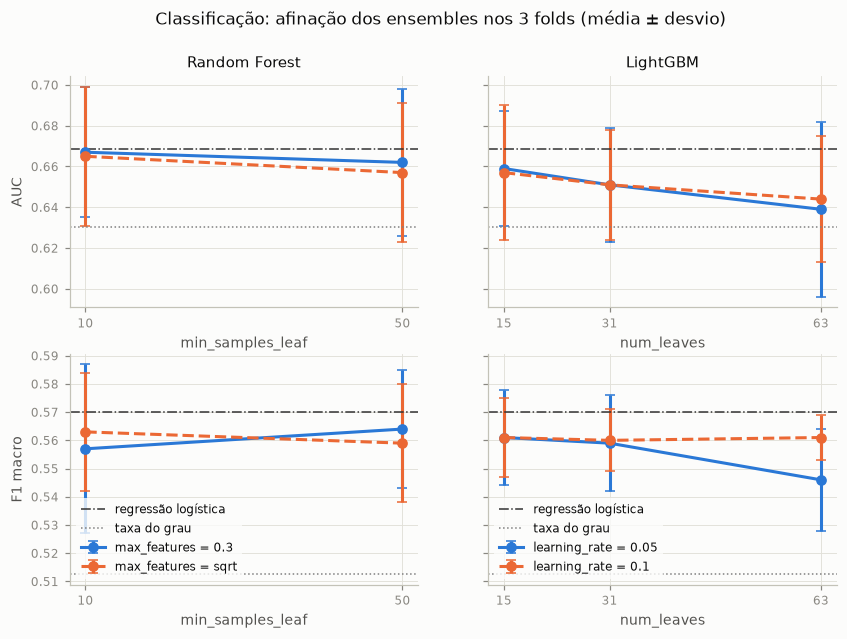

In [19]:
# Afinação dos ensembles: AUC e F1 macro (média ± desvio nos 3 folds)
best = runner.best().set_index("model")
forest, boosting = grid_table("Random Forest"), grid_table("LightGBM")

fig, axes = plt.subplots(2, 2, figsize=(9, 6), sharey="row")
panels = [(forest, "min_samples_leaf", "max_features"), (boosting, "num_leaves", "learning_rate")]
for row, metric, label in [(0, "auc", "AUC"), (1, "f1_macro", "F1 macro")]:
    for ax, (table, x, group) in zip(axes[row], panels):
        for (value, part), style in zip(table.groupby(group, sort=False), ["-", "--"]):
            ax.errorbar(part[x], part[f"{metric}_mean"], yerr=part[f"{metric}_std"], marker="o",
                        capsize=3, linestyle=style, label=f"{group} = {value}")
        ax.axhline(best.loc["Regressão logística", f"{metric}_mean"], color="0.2", linewidth=1,
                   linestyle="-.", label="regressão logística")
        ax.axhline(best.loc["Taxa do grau", f"{metric}_mean"], color="0.5", linewidth=1,
                   linestyle=":", label="taxa do grau")
        ax.set(xlabel=x, xticks=sorted(table[x].unique()))
    axes[row, 0].set_ylabel(label)
axes[0, 0].set_title("Random Forest")
axes[0, 1].set_title("LightGBM")
axes[1, 0].legend(fontsize=8)
axes[1, 1].legend(fontsize=8)
fig.suptitle("Classificação: afinação dos ensembles nos 3 folds (média ± desvio)")
fig.savefig(config.FIGURES_DIR / "mod_cls_ensembles.png")
plt.show()

In [20]:
# Melhor configuração de cada um, fold a fold, com o limiar escolhido
pd.concat({name: per_fold(name) for name in ENSEMBLES})

limiar  previstos Default (%)  f1_macro  accuracy  \
              fold                                                      
Random Forest 1       0.52                   24.2     0.542     0.719   
              2       0.52                   12.3     0.584     0.829   
              3       0.52                    9.8     0.565     0.840   
LightGBM      1       0.52                   21.0     0.552     0.743   
              2       0.52                   12.6     0.567     0.820   
              3       0.52                   10.0     0.565     0.839   

                    recall_default    auc  
              fold                         
Random Forest 1              0.357  0.622  
              2              0.281  0.691  
              3              0.211  0.674  
LightGBM      1              0.329  0.608  
              2              0.253  0.655  
              3              0.212  0.668

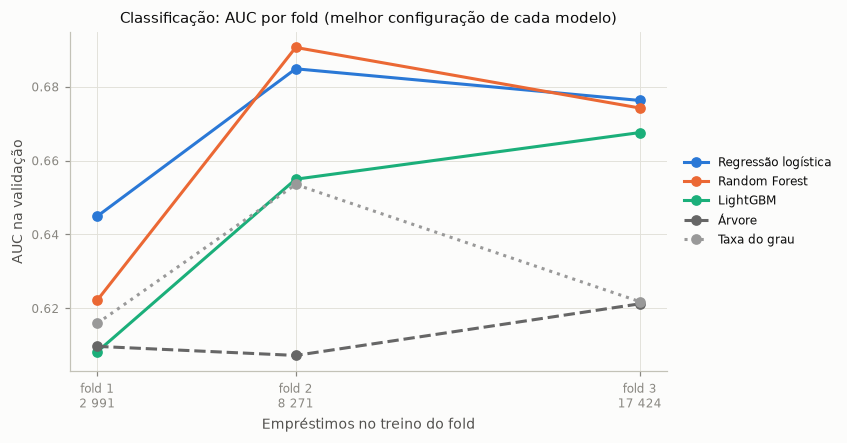

model,Regressão logística,Random Forest,LightGBM,Árvore,Taxa do grau
fold,,,,,
1,0.645,0.622,0.608,0.610,0.616
2,0.685,0.691,0.655,0.607,0.654
3,0.676,0.674,0.668,0.621,0.622


In [21]:
# AUC de cada fold (melhor configuração de cada modelo) contra o tamanho do treino
chosen = runner.best()[["model", "config_id"]]
rows = runner.results().merge(chosen, on=["model", "config_id"])
auc = rows.pivot_table(index="fold", columns="model", values="auc")
n_train = rows.groupby("fold")["n_train"].max()

styles = {"Regressão logística": {"color": CATEGORICAL[0]},
          "Random Forest": {"color": CATEGORICAL[1]},
          "LightGBM": {"color": CATEGORICAL[2]},
          "Árvore": {"color": "0.4", "linestyle": "--"},
          "Taxa do grau": {"color": "0.6", "linestyle": ":"}}
fig, ax = plt.subplots(figsize=(7, 4))
for model, style in styles.items():
    ax.plot(n_train.values, auc[model].values, marker="o", label=model, **style)
ax.set(xticks=n_train.values, xlabel="Empréstimos no treino do fold", ylabel="AUC na validação",
       title="Classificação: AUC por fold (melhor configuração de cada modelo)")
ax.set_xticklabels([f"fold {fold}\n{n:,}".replace(",", " ") for fold, n in n_train.items()])
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
fig.savefig(config.FIGURES_DIR / "mod_cls_auc_por_fold.png")
plt.show()

auc.loc[:, list(styles)].round(3)

In [22]:
# Tabela de comparação até aqui
runner.comparison_table()

,params,n_train,threshold,f1_macro,f1_micro,precision_macro,precision_micro,recall_macro,recall_micro,accuracy,recall_default,auc,fit_seconds
model,,,,,,,,,,,,,
MLP,"{""hidden_layers"": [256, 128, 64], ""learning_ra...",9562,0.56,0.573 ± 0.008,0.819 ± 0.023,0.571 ± 0.007,0.819 ± 0.023,0.575 ± 0.009,0.819 ± 0.023,0.819 ± 0.023,0.257 ± 0.005,0.666 ± 0.025,3.7
Regressão logística,"{""C"": 0.1}",9562,0.56,0.570 ± 0.010,0.814 ± 0.028,0.567 ± 0.009,0.814 ± 0.028,0.573 ± 0.012,0.814 ± 0.028,0.814 ± 0.028,0.259 ± 0.020,0.669 ± 0.021,0.1
Random Forest,"{""max_features"": 0.3, ""min_samples_leaf"": 50}",9562,0.52,0.564 ± 0.021,0.796 ± 0.067,0.564 ± 0.019,0.796 ± 0.067,0.573 ± 0.014,0.796 ± 0.067,0.796 ± 0.067,0.283 ± 0.073,0.662 ± 0.036,1.0
LightGBM,"{""learning_rate"": 0.1, ""num_leaves"": 63}",9562,0.52,0.561 ± 0.008,0.801 ± 0.051,0.560 ± 0.009,0.801 ± 0.051,0.568 ± 0.004,0.801 ± 0.051,0.801 ± 0.051,0.265 ± 0.059,0.644 ± 0.031,0.4
kNN,"{""n_neighbors"": 101, ""weights"": ""distance""}",9562,0.52,0.555 ± 0.011,0.792 ± 0.026,0.551 ± 0.009,0.792 ± 0.026,0.564 ± 0.013,0.792 ± 0.026,0.792 ± 0.026,0.266 ± 0.010,0.642 ± 0.028,0.0
Árvore,"{""max_depth"": 6, ""min_samples_leaf"": 50}",9562,0.62,0.541 ± 0.011,0.816 ± 0.051,0.546 ± 0.004,0.816 ± 0.051,0.542 ± 0.018,0.816 ± 0.051,0.816 ± 0.051,0.187 ± 0.094,0.613 ± 0.007,0.1
Taxa do grau,{},9562,0.21,0.513 ± 0.045,0.733 ± 0.174,0.550 ± 0.009,0.733 ± 0.174,0.561 ± 0.041,0.733 ± 0.174,0.733 ± 0.174,0.344 ± 0.298,0.630 ± 0.020,0.0
Classe maioritária,{},9562,0.05,0.469 ± 0.005,0.882 ± 0.017,0.441 ± 0.008,0.882 ± 0.017,0.500 ± 0.000,0.882 ± 0.017,0.882 ± 0.017,0.000 ± 0.000,0.500 ± 0.000,0.0


**Leitura.**

*Random Forest*

- **A grelha quase não importa:** as quatro configurações ficam entre 0,557 e 0,564 de F1 macro e entre 0,657 e 0,667 de AUC. As diferenças são menores do que o desvio entre folds (0,02 a 0,036). O runner escolhe `max_features = 0.3` e `min_samples_leaf = 50` (F1 macro 0,564 ± 0,021, AUC 0,662 ± 0,036).
- **O limiar muda com a configuração:** 0,40–0,44 com folhas de 10 e 0,51–0,52 com folhas de 50. As probabilidades da Random Forest dependem dos hiperparâmetros (não são probabilidades calibradas), e é por isso que o limiar se escolhe para cada configuração.
- **O *bagging* resolve o problema da árvore isolada:** a AUC sobe de 0,613 (uma árvore) para 0,662. No fold 2, a árvore fica em 0,607 e a floresta em 0,691. Em média, os erros de 300 árvores diferentes anulam-se, e a variância baixa.

*LightGBM*

- **Árvores mais pequenas ordenam melhor:** a AUC desce quando o `num_leaves` sobe (0,659 → 0,651 → 0,639 com `learning_rate = 0,05`). Com pouco sinal e poucos dados, árvores com muitas folhas aprendem ruído.
- **A escolha pelo F1 macro é um empate:** o runner escolhe `learning_rate = 0,1` e `num_leaves = 63` (F1 macro 0,561 ± 0,008). Três configurações têm o mesmo F1 macro (0,561), e a escolhida tem a pior AUC das três (0,644, contra 0,659 de `0,05 / 15`). Mantemos o F1 macro como critério de escolha, porque é o que o plano fixou para todos os modelos, mas a diferença entre estas três configurações não é real.
- **A paragem antecipada para muito cedo:** usa entre 5 e 79 árvores, do máximo de 500. O número cresce com os dados (5–31 no fold 1, 16–53 no fold 2, 41–79 no fold 3). O sinal é fraco: depois de algumas dezenas de correções pequenas, as árvores novas já só ajustam ruído do treino e a AUC nos empréstimos mais recentes deixa de subir.
- **A validação interna do fold 1 é pequena:** 449 empréstimos (novembro e dezembro de 2008), com só 77 *Default*. Uma AUC calculada com 77 positivos tem muito ruído, por isso a paragem pode acontecer cedo de mais (5 árvores em `0,05 / 63`). Isto ajuda a explicar o fold 1 do LightGBM: AUC de 0,608, abaixo da taxa do grau (0,616).

*Comparação com a regressão logística*

- **Nenhum *ensemble* passa a regressão logística:** F1 macro 0,570 (logística), 0,564 (Random Forest) e 0,561 (LightGBM); AUC 0,669, 0,662 e 0,644. As diferenças de F1 macro são menores do que o desvio entre folds, por isso não se pode dizer que a logística é melhor do que a Random Forest; o que se pode dizer é que os *ensembles* não acrescentam nada. A comparação formal (*bootstrap* emparelhado) fica para a tabela final.
- **A diferença depende do tamanho do treino** (figura da AUC por fold). Dentro de cada fold, a Random Forest fica 0,023 abaixo da logística no fold 1 (2 991 empréstimos), 0,006 acima no fold 2 e 0,002 abaixo no fold 3. O LightGBM fica 0,037, 0,030 e 0,008 abaixo. Os modelos flexíveis precisam de mais dados para aprender as interações; com até 17 000 empréstimos, chegam no máximo ao nível da logística. A comparação justa é dentro do mesmo fold, porque de fold para fold também muda o ano de validação.
- **Porque é que o modelo linear aguenta:** os fatores de risco principais (grau e taxa de juro, FICO, DTI, rendimento) têm efeitos quase monótonos nos *log-odds* do *default*, e as interações acrescentam pouco. É um resultado frequente em *credit scoring* com dados tabulares deste tamanho.
- **Os *ensembles* são menos estáveis no tempo:** no fold 1 marcam 21–24% dos empréstimos como *Default* (logística: 15%), com *accuracy* de 0,72–0,74. O desvio do recall de *Default* é 0,06–0,07, contra 0,02 na logística. Com só 2 991 empréstimos no fold 1, é provável que as árvores aprendam particularidades de 2007–2008 que não se repetem em 2009.

**Custo:** a Random Forest leva cerca de 1 s por ajuste (300 árvores, em paralelo) e o LightGBM menos de 1 s, porque para cedo. Os 30 ajustes correm em cerca de 22 s, por isso não há limitações computacionais nesta tarefa.

## 5. kNN de raiz

O enunciado pede um kNN implementado de raiz em NumPy, aplicado às duas tarefas. A implementação é do João (`src/lending/knn.py`). O notebook `04a_knn.ipynb` explica o algoritmo e a estrutura de dados, e confirma que dá os mesmos resultados do scikit-learn. Aqui o kNN entra na mesma validação cruzada dos outros modelos.

**Como prevê.** O kNN não aprende parâmetros: o "treino" é só guardar os empréstimos do treino do fold. Para cada empréstimo a prever:

1. calcula a distância euclidiana a todos os empréstimos do treino, nas colunas padronizadas pelo pipeline (sem padronização, as colunas com valores grandes, como o rendimento, dominavam a distância);
2. escolhe os $k$ mais próximos;
3. a "probabilidade" de *Default* é a proporção ponderada de *Default* entre esses $k$. Cada vizinho vota com o peso da distância, $v_i$ (igual para todos com `uniform`, $1/d$ com `distance`, em que os mais próximos contam mais), vezes o peso da sua classe, $w_{y_i}$.

$$\hat p(x) = \frac{\sum_{i \in N_k(x)} v_i\, w_{y_i}\, [y_i = \text{Default}]}{\sum_{i \in N_k(x)} v_i\, w_{y_i}}, \qquad v_i = 1 \text{ ou } v_i = 1/d(x, x_i)$$

- **Grelha:** $k$ {5, 15, 31, 51, 101} × pesos {`uniform`, `distance`}. Com $k$ pequeno, a estimativa é muito local e tem muita variância; com $k$ grande, é mais estável mas mais enviesada (mistura empréstimos menos parecidos).
- **Sem `dti_with_loan`:** é `dti + installment_to_income`, por isso contava duas vezes a mesma informação na distância.
- **Força bruta com cache:** com cerca de 115 colunas, uma KD-tree não consegue descartar ramos (maldição da dimensionalidade), por isso as distâncias são todas calculadas, por blocos, com um produto de matrizes. A pesquisa devolve sempre os 101 vizinhos mais próximos e guarda-os. As 10 configurações de um fold usam a mesma pesquisa, cada uma com os primeiros $k$.
- **Pesos das classes:** `class_weight="balanced"`, como nos outros modelos supervisionados: $w_1 = n / (2 n_\text{Default})$ e $w_0 = n / (2 n_\text{Good})$, calculados no treino do fold. Um vizinho *Default* vale $(1 - r)/r$ vizinhos *Good standing*, com $r$ a taxa de *default* do treino: cerca de 3,6 no fold 1 e 6,4 no fold 3. Sem estes pesos, a proporção de *Default* entre os vizinhos ficava na escala da taxa de *default* do treino (12–22%), como a baseline do grau. O fim da secção mostra o que isso fazia ao limiar.

In [23]:
runner.run(data, [specs["kNN"]]);

In [24]:
grid_table("kNN")

,n_neighbors,weights,threshold,f1_macro_mean,f1_macro_std,auc_mean,auc_std,recall_default_mean,fit_seconds
0,5,distance,0.68,0.530,0.004,0.559,0.004,0.176,0.025
1,5,uniform,0.62,0.529,0.003,0.559,0.004,0.176,0.025
2,15,distance,0.61,0.543,0.002,0.597,0.013,0.194,0.023
3,15,uniform,0.57,0.543,0.001,0.596,0.014,0.215,0.025
4,31,distance,0.57,0.548,0.003,0.621,0.018,0.199,0.023
5,31,uniform,0.56,0.546,0.003,0.621,0.019,0.193,0.024
6,51,distance,0.54,0.553,0.004,0.633,0.023,0.246,0.025
7,51,uniform,0.55,0.552,0.002,0.632,0.023,0.213,0.025
8,101,distance,0.52,0.555,0.011,0.642,0.028,0.266,0.021
9,101,uniform,0.52,0.553,0.012,0.641,0.028,0.277,0.020


In [25]:
# Tempo de previsão (s) de cada configuração por fold: só a primeira calcula as distâncias,
# as outras 9 reutilizam os 101 vizinhos guardados
(runner.results().query("model == 'kNN'")
 .pivot_table(index="params", columns="fold", values="predict_seconds", sort=False))

fold,1,2,3
params,,,
"{""n_neighbors"": 5, ""weights"": ""uniform""}",0.681,1.701,3.375
"{""n_neighbors"": 5, ""weights"": ""distance""}",0.011,0.017,0.031
"{""n_neighbors"": 15, ""weights"": ""uniform""}",0.014,0.019,0.030
"{""n_neighbors"": 15, ""weights"": ""distance""}",0.014,0.019,0.029
"{""n_neighbors"": 31, ""weights"": ""uniform""}",0.016,0.022,0.034
"{""n_neighbors"": 31, ""weights"": ""distance""}",0.020,0.022,0.034
"{""n_neighbors"": 51, ""weights"": ""uniform""}",0.018,0.035,0.043
"{""n_neighbors"": 51, ""weights"": ""distance""}",0.020,0.034,0.040
"{""n_neighbors"": 101, ""weights"": ""uniform""}",0.021,0.036,0.056


In [26]:
# Melhor configuração pelo F1 macro, fold a fold, com o limiar escolhido
per_fold("kNN")

,limiar,previstos Default (%),f1_macro,accuracy,recall_default,auc
fold,,,,,,
1,0.52,17.1,0.543,0.762,0.254,0.610
2,0.52,14.1,0.563,0.809,0.269,0.665
3,0.52,14.8,0.559,0.804,0.275,0.650


**Porque são precisos os pesos das classes.** Para ver o efeito, a célula seguinte volta a ajustar as 10 configurações com votos simples (`class_weight=None`), nos mesmos folds e com o mesmo pré-processamento, e compara-as com as do catálogo. Com votos simples, a proporção de *Default* entre os vizinhos acompanha a taxa de *default* do treino, que desce de fold para fold. Com um limiar fixo, o kNN marca então cada vez menos empréstimos, como a baseline do grau no passo 1.

As duas proporções estão ligadas por

$$\hat p_w = \frac{w_1\, \hat p}{w_1\, \hat p + w_0\, (1 - \hat p)}$$

Dentro de cada fold é uma transformação crescente, por isso a AUC de cada fold é a mesma. Mudam o nível das probabilidades e, com ele, o limiar e o F1 macro. A célula também confirma a fórmula nas previsões.

In [27]:
# As mesmas 10 configurações com votos simples (class_weight=None): só para comparar, não entram no CSV
plain = []
for fold, (tr, va) in enumerate(runner.splitter.split(ordered["issue_d"]), start=1):
    prep = runner.make_preprocessor()
    A_tr, A_va = prep.fit_transform(X.iloc[tr], y.iloc[tr]), prep.transform(X.iloc[va])
    dropper = ColumnDropper(COLLINEAR_DROP).fit(A_tr)
    A_tr, A_va = dropper.transform(A_tr), dropper.transform(A_va)
    for cid, params in specs["kNN"].configs():
        model = KNNClassifier(search_k=max(KNN_K), class_weight=None, **params).fit(A_tr, y.iloc[tr])
        plain.append(pd.DataFrame({"config_id": cid, "fold": fold, "row": va,
                                   "p_simples": positive_proba(model, A_va)}))
plain = pd.concat(plain, ignore_index=True)

# Taxa de default do treino de cada fold (a única informação usada nos pesos: nada da validação)
train_rate = {fold: is_default.iloc[tr].mean()
              for fold, (tr, va) in enumerate(runner.splitter.split(ordered["issue_d"]), start=1)}


def vote_summary(y_true, p, fold):
    """Limiar escolhido fora do fold, F1 macro por fold e percentagem de Default previstos por fold."""
    threshold, _ = best_threshold(y_true, p)
    f1 = pd.Series([classification_metrics(y_true.loc[idx], p.loc[idx], threshold)["f1_macro"]
                    for idx in fold.groupby(fold).groups.values()])
    flagged = p.ge(threshold).groupby(fold).mean().mul(100).round(1)
    return {"limiar": threshold, "f1_macro_mean": f1.mean(), "f1_macro_std": f1.std(),
            **{f"Default previstos fold {f} (%)": share for f, share in flagged.items()}}


rows, gap = [], 0.0
for cid, params in specs["kNN"].configs():
    oof = runner.oof("kNN", cid).merge(plain.query("config_id == @cid"), on=["fold", "row"])
    rate = oof["fold"].map(train_rate)
    w1, w0 = 1 / (2 * rate), 1 / (2 * (1 - rate))
    formula = w1 * oof["p_simples"] / (w1 * oof["p_simples"] + w0 * (1 - oof["p_simples"]))
    gap = max(gap, (formula - oof["p_default"]).abs().max())
    for kind, column in [("ponderados pela classe (catálogo)", "p_default"), ("simples", "p_simples")]:
        rows.append({**params, "votos": kind, **vote_summary(oof["y_true"], oof[column], oof["fold"])})
votes = pd.DataFrame(rows)
print(f"Maior diferença entre a fórmula e as previsões do catálogo: {gap:.1e}")
votes.sort_values(["votos", "f1_macro_mean"], ascending=[True, False]).round(3).reset_index(drop=True)

Maior diferença entre a fórmula e as previsões do catálogo: 5.6e-16


,n_neighbors,weights,votos,limiar,f1_macro_mean,f1_macro_std,Default previstos fold 1 (%),Default previstos fold 2 (%),Default previstos fold 3 (%)
0,101,distance,ponderados pela classe (catálogo),0.52,0.555,0.011,17.1,14.1,14.8
1,101,uniform,ponderados pela classe (catálogo),0.52,0.553,0.012,17.1,15.8,15.6
2,51,distance,ponderados pela classe (catálogo),0.54,0.553,0.004,15.5,13.6,13.5
3,51,uniform,ponderados pela classe (catálogo),0.55,0.552,0.002,15.8,9.4,10.9
4,31,distance,ponderados pela classe (catálogo),0.57,0.548,0.003,12.4,11.1,10.7
5,31,uniform,ponderados pela classe (catálogo),0.56,0.546,0.003,12.1,11.0,10.5
6,15,distance,ponderados pela classe (catálogo),0.61,0.543,0.002,11.8,11.5,11.7
7,15,uniform,ponderados pela classe (catálogo),0.57,0.543,0.001,11.7,11.4,16.4
8,5,distance,ponderados pela classe (catálogo),0.68,0.530,0.004,18.2,10.8,7.6
9,5,uniform,ponderados pela classe (catálogo),0.62,0.529,0.003,18.9,10.7,7.3


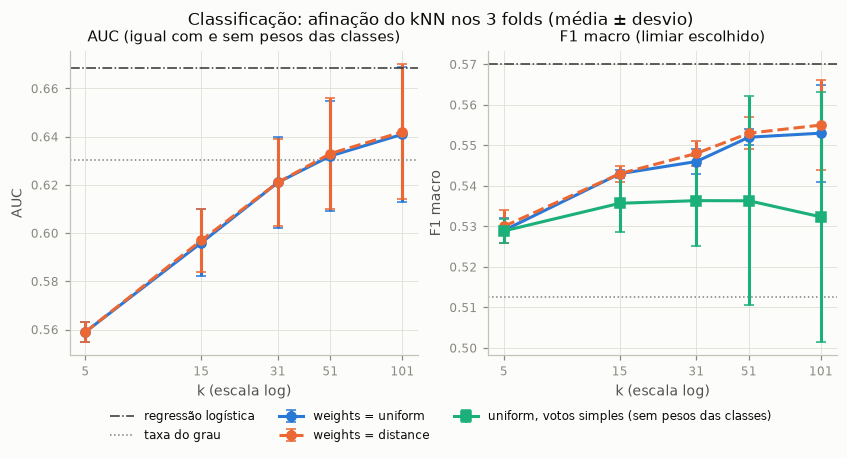

In [28]:
# Afinação do kNN: AUC e F1 macro (média ± desvio nos 3 folds) em função de k
best = runner.best().set_index("model")
knn = grid_table("kNN")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, metric, label in [(axes[0], "auc", "AUC"), (axes[1], "f1_macro", "F1 macro")]:
    for weights, style in zip(["uniform", "distance"], ["-", "--"]):
        part = knn[knn["weights"] == weights]
        ax.errorbar(part["n_neighbors"], part[f"{metric}_mean"], yerr=part[f"{metric}_std"], marker="o",
                    capsize=3, linestyle=style, label=f"weights = {weights}")
    ax.axhline(best.loc["Regressão logística", f"{metric}_mean"], color="0.2", linewidth=1,
               linestyle="-.", label="regressão logística")
    ax.axhline(best.loc["Taxa do grau", f"{metric}_mean"], color="0.5", linewidth=1,
               linestyle=":", label="taxa do grau")
    ax.set(xscale="log", xlabel="k (escala log)", ylabel=label)
    ax.set_xticks(KNN_K, labels=KNN_K)
    ax.minorticks_off()
part = votes.query("votos == 'simples' and weights == 'uniform'")
axes[1].errorbar(part["n_neighbors"], part["f1_macro_mean"], yerr=part["f1_macro_std"], marker="s",
                 capsize=3, color=CATEGORICAL[2], label="uniform, votos simples (sem pesos das classes)")
axes[0].set_title("AUC (igual com e sem pesos das classes)")
axes[1].set_title("F1 macro (limiar escolhido)")
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 0.0))
fig.suptitle("Classificação: afinação do kNN nos 3 folds (média ± desvio)")
fig.savefig(config.FIGURES_DIR / "mod_cls_knn.png")
plt.show()

In [29]:
# Fora da grelha: k maiores do que 101 (só a AUC; não entra na tabela de comparação)
# Também mede a concentração das distâncias: a distância do 1.º vizinho a dividir pela do 101.º
LARGE_K = [101, 201, 401, 801]
rows = []
for fold, (tr, va) in enumerate(runner.splitter.split(ordered["issue_d"]), start=1):
    prep = runner.make_preprocessor()
    A_tr, A_va = prep.fit_transform(X.iloc[tr], y.iloc[tr]), prep.transform(X.iloc[va])
    dropper = ColumnDropper(COLLINEAR_DROP).fit(A_tr)
    A_tr, A_va = dropper.transform(A_tr), dropper.transform(A_va)
    row = {"fold": fold, "treino": len(tr), "colunas": A_tr.shape[1]}
    for k in LARGE_K:
        model = KNNClassifier(n_neighbors=k, search_k=max(LARGE_K), class_weight="balanced").fit(A_tr, y.iloc[tr])
        row[f"AUC k = {k}"] = roc_auc_score(is_default.iloc[va], positive_proba(model, A_va))
    distances, _ = model.kneighbors(A_va, n_neighbors=101)
    row["d(1.º) / d(101.º), mediana"] = np.median(distances[:, 0] / distances[:, 100])
    rows.append(row)
pd.DataFrame(rows).set_index("fold").round(3)

,treino,colunas,AUC k = 101,AUC k = 201,AUC k = 401,AUC k = 801,"d(1.º) / d(101.º), mediana"
fold,,,,,,,
1,2991,121,0.609,0.614,0.616,0.614,0.647
2,8271,118,0.664,0.666,0.667,0.670,0.654
3,17424,115,0.649,0.655,0.660,0.663,0.668


In [30]:
# Tabela de comparação até aqui
runner.comparison_table()

,params,n_train,threshold,f1_macro,f1_micro,precision_macro,precision_micro,recall_macro,recall_micro,accuracy,recall_default,auc,fit_seconds
model,,,,,,,,,,,,,
MLP,"{""hidden_layers"": [256, 128, 64], ""learning_ra...",9562,0.56,0.573 ± 0.008,0.819 ± 0.023,0.571 ± 0.007,0.819 ± 0.023,0.575 ± 0.009,0.819 ± 0.023,0.819 ± 0.023,0.257 ± 0.005,0.666 ± 0.025,3.7
Regressão logística,"{""C"": 0.1}",9562,0.56,0.570 ± 0.010,0.814 ± 0.028,0.567 ± 0.009,0.814 ± 0.028,0.573 ± 0.012,0.814 ± 0.028,0.814 ± 0.028,0.259 ± 0.020,0.669 ± 0.021,0.1
Random Forest,"{""max_features"": 0.3, ""min_samples_leaf"": 50}",9562,0.52,0.564 ± 0.021,0.796 ± 0.067,0.564 ± 0.019,0.796 ± 0.067,0.573 ± 0.014,0.796 ± 0.067,0.796 ± 0.067,0.283 ± 0.073,0.662 ± 0.036,1.0
LightGBM,"{""learning_rate"": 0.1, ""num_leaves"": 63}",9562,0.52,0.561 ± 0.008,0.801 ± 0.051,0.560 ± 0.009,0.801 ± 0.051,0.568 ± 0.004,0.801 ± 0.051,0.801 ± 0.051,0.265 ± 0.059,0.644 ± 0.031,0.4
kNN,"{""n_neighbors"": 101, ""weights"": ""distance""}",9562,0.52,0.555 ± 0.011,0.792 ± 0.026,0.551 ± 0.009,0.792 ± 0.026,0.564 ± 0.013,0.792 ± 0.026,0.792 ± 0.026,0.266 ± 0.010,0.642 ± 0.028,0.0
Árvore,"{""max_depth"": 6, ""min_samples_leaf"": 50}",9562,0.62,0.541 ± 0.011,0.816 ± 0.051,0.546 ± 0.004,0.816 ± 0.051,0.542 ± 0.018,0.816 ± 0.051,0.816 ± 0.051,0.187 ± 0.094,0.613 ± 0.007,0.1
Taxa do grau,{},9562,0.21,0.513 ± 0.045,0.733 ± 0.174,0.550 ± 0.009,0.733 ± 0.174,0.561 ± 0.041,0.733 ± 0.174,0.733 ± 0.174,0.344 ± 0.298,0.630 ± 0.020,0.0
Classe maioritária,{},9562,0.05,0.469 ± 0.005,0.882 ± 0.017,0.441 ± 0.008,0.882 ± 0.017,0.500 ± 0.000,0.882 ± 0.017,0.882 ± 0.017,0.000 ± 0.000,0.500 ± 0.000,0.0


**Leitura.**

*A grelha*

- **A AUC sobe sempre com $k$:** 0,559 com $k = 5$, depois 0,596, 0,621, 0,632 e 0,641 com $k = 101$ (`uniform`). Com $k = 5$, a "probabilidade" só tem 6 valores possíveis e depende de muito poucos empréstimos, por isso tem muita variância. Com mais vizinhos, a proporção de *Default* estima melhor o risco daquela zona. Com um sinal fraco, compensa fazer a média sobre mais vizinhos.
- **O F1 macro também sobe com $k$:** de 0,529 com $k = 5$ para 0,555 ± 0,011 com $k = 101$ e `distance`, a configuração escolhida. As duas métricas escolhem o mesmo $k$.
- **`uniform` e `distance` dão o mesmo** (a AUC difere no máximo 0,001). Com 115 a 121 colunas, as distâncias concentram-se: na mediana, o vizinho mais próximo está a 65–67% da distância do 101.º. Os pesos $1/d$ variam tipicamente só cerca de 1,5 vezes entre vizinhos, quase como votos iguais. É um efeito da maldição da dimensionalidade.
- **O limiar fica perto de 0,5, como nos outros modelos com pesos:** entre 0,52 e 0,68, mais alto com $k$ pequeno. A partir de $k = 15$, o F1 macro com o limiar de 0,5 fica entre 0,52 e 0,56 em cada fold.

*Os pesos das classes*

- **Com pesos, a percentagem de *Default* previstos é estável no tempo.** Com $k = 101$ e `distance`, o limiar é 0,52 e marca 17,1%, 14,1% e 14,8% dos empréstimos nos três folds. O recall de *Default* fica entre 0,25 e 0,28 (0,266 ± 0,010), o mais estável dos modelos supervisionados.
- **Sem pesos, o kNN teria o problema da baseline do grau.** Com votos simples, a proporção de *Default* entre os vizinhos segue a taxa de *default* do treino, e o limiar escolhido desce para 0,17–0,25. A melhor configuração com votos simples (`k = 31`, `distance`, limiar 0,21) marcava 27,8% no fold 1, 11,1% no fold 2 e 6,0% no fold 3, com F1 macro 0,538 ± 0,012.
- **Sem pesos, o F1 macro e a AUC escolhiam $k$ diferentes.** Com $k = 101$ e votos simples, a ordenação é a mesma (AUC 0,642), mas as probabilidades ficam ainda mais perto da taxa de *default* do treino. A deriva era maior (45,0% no fold 1 e 7,6% no fold 3) e o F1 macro instável (0,529 ± 0,045). Por isso o F1 macro preferia $k = 31$. Os pesos corrigem o nível das probabilidades sem mudar a ordenação, e o F1 macro passa a seguir a AUC.
- **O fold 1 é o mais fraco** (F1 macro 0,543, AUC 0,610). Só tem 2 991 empréstimos de treino, e 101 vizinhos já são 3,4% do treino, por isso as vizinhanças são largas.

*$k$ maiores do que a grelha*

- A melhor AUC está no limite da grelha ($k = 101$), por isso testámos valores maiores. Nos folds 2 e 3, a AUC ainda sobe um pouco (no fold 3, de 0,649 para 0,663 com $k = 801$). No fold 1, o máximo é em $k = 401$ (0,616), porque 801 vizinhos já são mais de um quarto dos 2 991 empréstimos do treino.
- Em todos os folds fica abaixo da logística (0,645, 0,685 e 0,676), por isso o limite da grelha não esconde um modelo melhor. Com $k$ muito grande, o kNN aproxima-se de uma média suave do risco em zonas largas, o tipo de função que a logística aprende diretamente.

*Comparação*

- Na tabela, o kNN (`k = 101`, `distance`) tem F1 macro 0,555 ± 0,011 e AUC 0,642 ± 0,028. Fica em 4.º lugar no F1 macro, abaixo da logística (0,570), da Random Forest (0,564) e do LightGBM (0,561), e acima da árvore (0,541) e das baselines. Na AUC, está ao nível do LightGBM (0,644) e acima da taxa do grau (0,630) e da árvore (0,613).
- As diferenças para a Random Forest e para o LightGBM são da ordem do desvio entre folds. A logística fica à frente nas duas métricas e, na AUC, em todos os folds (0,645, 0,685 e 0,676, contra 0,610, 0,665 e 0,650 do kNN).

**Custo:** o *fit* só guarda os dados (0,02 s). Na previsão, a primeira configuração de cada fold calcula as distâncias (0,7 s, 1,7 s e 3,4 s), e as outras 9 reutilizam os vizinhos guardados (menos de 0,06 s cada). A grelha toda corre em cerca de 10 s.

## 6. MLP (rede neuronal densa em Keras)

O enunciado pede um modelo de *deep learning* (TensorFlow ou PyTorch) nas duas tarefas, com a arquitetura justificada. A implementação é a do bloco 3 (`src/lending/deep.py`, `KerasMLPClassifier`), documentada em `docs/04_modelos/mlp.md`. Aqui entra na mesma validação cruzada dos outros modelos.

**Arquitetura.** Entrada (117 a 123 colunas do pré-processamento) → camadas densas com ReLU, cada uma seguida de *dropout* 0,2 → uma unidade sigmoide.

- **Camadas densas:** os dados são tabulares (uma linha por empréstimo, sem estrutura espacial nem sequencial), por isso convoluções ou redes recorrentes não se aplicam.
- **ReLU** nas camadas escondidas: $\max(0, z)$ não satura para valores positivos, por isso o gradiente não se apaga ao atravessar várias camadas (o problema das sigmoides).
- ***Dropout* 0,2:** em cada passo do treino, 20% dos neurónios de cada camada são desligados ao acaso. A rede não pode depender de neurónios específicos, o que reduz o sobreajustamento. Na previsão, o *dropout* está desligado.
- **Saída sigmoide e entropia cruzada binária:** a saída fica entre 0 e 1 e lê-se como probabilidade. A entropia cruzada castiga muito uma probabilidade confiante e errada.
- **Adam**, com lotes de 512 empréstimos.
- **Pesos das classes:** `class_weight="balanced"` na perda, calculado só nas linhas que treinam a rede, como nos outros modelos.
- **Paragem antecipada temporal:** os últimos 15% do treino de cada fold (os empréstimos mais recentes) ficam de fora como validação interna. No fim de cada época mede-se a AUC nessas linhas. Se não melhorar durante 5 épocas, o treino pára e ficam os pesos da melhor época. O máximo são 50 épocas. O critério é a AUC e não a perda, porque o Keras aplica os pesos das classes à perda do treino mas não à da validação.

**Grelha:** 3 arquiteturas × 2 taxas de aprendizagem = 6 configurações.

| Arquitetura | Camadas escondidas | Parâmetros (117–123 colunas) |
|---|---|---|
| (64) | 1 | 7 617 – 8 001 |
| (128, 64) | 2 | 23 425 – 24 193 |
| (256, 128, 64) | 3 | 71 425 – 72 961 |

- **Taxas de aprendizagem:** 0,001, o valor de referência do Adam, e 0,0003, com passos mais pequenos (mais estável, mas precisa de mais épocas).
- **Poucos dados para tantos parâmetros:** no fold 1, a rede treina com 2 543 empréstimos (os outros 448 são a validação interna), menos do que os parâmetros de qualquer das três redes. O que trava o sobreajustamento é o *dropout* e, sobretudo, a paragem antecipada.

In [31]:
runner.run(data, [specs["MLP"]]);

In [32]:
grid_table("MLP")

,hidden_layers,learning_rate,threshold,f1_macro_mean,f1_macro_std,auc_mean,auc_std,recall_default_mean,fit_seconds
0,"(64,)",0.0003,0.53,0.565,0.018,0.665,0.029,0.318,6.954
1,"(64,)",0.0010,0.54,0.563,0.019,0.665,0.025,0.300,4.519
2,"(128, 64)",0.0003,0.54,0.566,0.019,0.666,0.028,0.296,6.146
3,"(128, 64)",0.0010,0.56,0.566,0.019,0.665,0.028,0.272,3.779
4,"(256, 128, 64)",0.0003,0.54,0.570,0.016,0.665,0.025,0.314,5.579
5,"(256, 128, 64)",0.0010,0.56,0.573,0.008,0.666,0.025,0.257,3.698


In [33]:
# Melhor configuração pelo F1 macro, fold a fold, com o limiar escolhido
per_fold("MLP")

,limiar,previstos Default (%),f1_macro,accuracy,recall_default,auc
fold,,,,,,
1,0.56,14.1,0.564,0.792,0.253,0.637
2,0.56,11.7,0.579,0.831,0.262,0.678
3,0.56,11.5,0.576,0.833,0.256,0.682


**Épocas e curvas de treino.** O runner não guarda as redes, por isso a célula seguinte volta a treinar as 6 configurações em cada fold, com a mesma semente e o mesmo pré-processamento. Mostra quantas épocas cada rede treinou e em qual parou, e confirma que a AUC é a mesma do runner.

In [34]:
# Volta a treinar as 6 configurações em cada fold: épocas corridas e melhor época (a que fica)
mlp_cid = runner.best().set_index("model").loc["MLP", "config_id"]
runner_auc = runner.results().query("model == 'MLP'").set_index(["config_id", "fold"])["auc"]
MAX_EPOCHS = specs["MLP"].make({}).max_epochs

matrices, histories, nets, epochs, gap = {}, {}, {}, {}, 0.0
for fold, (tr, va) in enumerate(runner.splitter.split(ordered["issue_d"]), start=1):
    prep = runner.make_preprocessor()
    A_tr, A_va = prep.fit_transform(X.iloc[tr], y.iloc[tr]), prep.transform(X.iloc[va])
    matrices[fold] = (A_tr, A_va, tr, va)
    for cid, params in specs["MLP"].configs():
        net = specs["MLP"].make(params).fit(A_tr, y.iloc[tr])
        auc = roc_auc_score(is_default.iloc[va], positive_proba(net, A_va))
        gap = max(gap, abs(auc - runner_auc[(cid, fold)]))
        histories[(cid, fold)] = net.history_
        if cid == mlp_cid:
            nets[fold] = net
        key = (str(tuple(params["hidden_layers"])), params["learning_rate"])
        epochs.setdefault(key, {})[f"fold {fold}"] = f"{net.n_epochs_} ({net.best_epoch_})"
print(f"Maior diferença de AUC para o runner: {gap:.1e}")
print(f"Épocas corridas (melhor época), máximo {MAX_EPOCHS}:")
pd.DataFrame.from_dict(epochs, orient="index").rename_axis(["arquitetura", "learning_rate"])

Maior diferença de AUC para o runner: 0.0e+00
Épocas corridas (melhor época), máximo 50:


fold 1   fold 2   fold 3
arquitetura    learning_rate                           
(64,)          0.0010         40 (35)  25 (20)  24 (19)
               0.0003         50 (50)  48 (43)  50 (45)
(128, 64)      0.0010         27 (22)   12 (7)   12 (7)
               0.0003         50 (47)  37 (32)  24 (19)
(256, 128, 64) 0.0010          11 (6)  16 (11)   13 (8)
               0.0003         30 (25)  31 (26)  17 (12)

In [35]:
# As redes que chegaram ao limite de épocas: com mais épocas, a AUC melhorava? (não entra no CSV)
rows = []
for (cid, fold), history in histories.items():
    if len(history["loss"]) < MAX_EPOCHS:
        continue
    params = dict(specs["MLP"].configs())[cid]
    A_tr, A_va, tr, va = matrices[fold]
    net = specs["MLP"].make(params).set_params(max_epochs=200).fit(A_tr, y.iloc[tr])
    rows.append({"fold": fold, "arquitetura": str(tuple(params["hidden_layers"])),
                 "learning_rate": params["learning_rate"],
                 f"AUC com {MAX_EPOCHS} épocas": runner_auc[(cid, fold)],
                 "épocas (melhor) com máximo 200": f"{net.n_epochs_} ({net.best_epoch_})",
                 "AUC com máximo 200": roc_auc_score(is_default.iloc[va], positive_proba(net, A_va))})
pd.DataFrame(rows).round({f"AUC com {MAX_EPOCHS} épocas": 3, "AUC com máximo 200": 3})

,fold,arquitetura,learning_rate,AUC com 50 épocas,épocas (melhor) com máximo 200,AUC com máximo 200
0,1,"(64,)",0.0003,0.631,100 (95),0.636
1,1,"(128, 64)",0.0003,0.634,52 (47),0.634
2,3,"(64,)",0.0003,0.680,50 (45),0.680


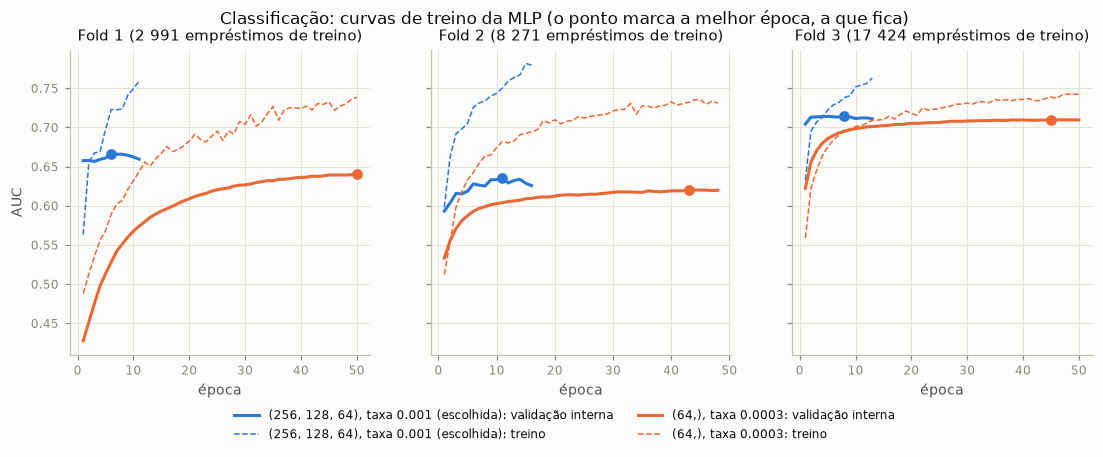

In [36]:
# Curvas de treino: AUC por época no treino (com dropout) e na validação interna (últimos 15%)
slow_cid = next(cid for cid, params in specs["MLP"].configs()
                if tuple(params["hidden_layers"]) == (64,) and params["learning_rate"] == 0.0003)
configs = dict(specs["MLP"].configs())
labels = {cid: f"{tuple(configs[cid]['hidden_layers'])}, taxa {configs[cid]['learning_rate']}"
          for cid in [mlp_cid, slow_cid]}
labels[mlp_cid] += " (escolhida)"

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, fold in zip(axes, [1, 2, 3]):
    for (cid, label), color in zip(labels.items(), CATEGORICAL):
        history = histories[(cid, fold)]
        epoch = np.arange(1, len(history["loss"]) + 1)
        ax.plot(epoch, history["val_auc"], color=color, label=f"{label}: validação interna")
        ax.plot(epoch, history["auc"], color=color, linestyle="--", linewidth=1, label=f"{label}: treino")
        best_epoch = int(np.argmax(history["val_auc"])) + 1
        ax.plot(best_epoch, history["val_auc"][best_epoch - 1], marker="o", color=color)
    n_train = f"{len(matrices[fold][2]):,}".replace(",", " ")
    ax.set(title=f"Fold {fold} ({n_train} empréstimos de treino)", xlabel="época")
axes[0].set_ylabel("AUC")
handles, names = axes[0].get_legend_handles_labels()
fig.legend(handles, names, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 0.0))
fig.suptitle("Classificação: curvas de treino da MLP (o ponto marca a melhor época, a que fica)")
fig.savefig(config.FIGURES_DIR / "mod_cls_mlp.png")
plt.show()

In [37]:
# A arquitetura escolhida, camada a camada (rede do fold 3)
net = nets[3]
layers = pd.DataFrame([{"camada": type(layer).__name__,
                        "neurónios": getattr(layer, "units", None),
                        "ativação": getattr(getattr(layer, "activation", None), "__name__", None),
                        "fração desligada": getattr(layer, "rate", None),
                        "parâmetros": layer.count_params()} for layer in net.model_.layers])
print(f"{net.n_features_in_} colunas de entrada, {layers['parâmetros'].sum():,} parâmetros; "
      f"pesos das classes: {net.class_weight_}")
layers

117 colunas de entrada, 71,425 parâmetros; pesos das classes: {'Default': 3.511379800853485, 'Good standing': 0.5830184222957014}


,camada,neurónios,ativação,fração desligada,parâmetros
0,Dense,256.0,relu,NaN,30208
1,Dropout,NaN,NaN,0.2,0
2,Dense,128.0,relu,NaN,32896
3,Dropout,NaN,NaN,0.2,0
4,Dense,64.0,relu,NaN,8256
5,Dropout,NaN,NaN,0.2,0
6,Dense,1.0,sigmoid,NaN,65


In [38]:
# Tabela de comparação até aqui (todos os modelos do catálogo)
runner.comparison_table()

,params,n_train,threshold,f1_macro,f1_micro,precision_macro,precision_micro,recall_macro,recall_micro,accuracy,recall_default,auc,fit_seconds
model,,,,,,,,,,,,,
MLP,"{""hidden_layers"": [256, 128, 64], ""learning_ra...",9562,0.56,0.573 ± 0.008,0.819 ± 0.023,0.571 ± 0.007,0.819 ± 0.023,0.575 ± 0.009,0.819 ± 0.023,0.819 ± 0.023,0.257 ± 0.005,0.666 ± 0.025,3.7
Regressão logística,"{""C"": 0.1}",9562,0.56,0.570 ± 0.010,0.814 ± 0.028,0.567 ± 0.009,0.814 ± 0.028,0.573 ± 0.012,0.814 ± 0.028,0.814 ± 0.028,0.259 ± 0.020,0.669 ± 0.021,0.1
Random Forest,"{""max_features"": 0.3, ""min_samples_leaf"": 50}",9562,0.52,0.564 ± 0.021,0.796 ± 0.067,0.564 ± 0.019,0.796 ± 0.067,0.573 ± 0.014,0.796 ± 0.067,0.796 ± 0.067,0.283 ± 0.073,0.662 ± 0.036,1.0
LightGBM,"{""learning_rate"": 0.1, ""num_leaves"": 63}",9562,0.52,0.561 ± 0.008,0.801 ± 0.051,0.560 ± 0.009,0.801 ± 0.051,0.568 ± 0.004,0.801 ± 0.051,0.801 ± 0.051,0.265 ± 0.059,0.644 ± 0.031,0.4
kNN,"{""n_neighbors"": 101, ""weights"": ""distance""}",9562,0.52,0.555 ± 0.011,0.792 ± 0.026,0.551 ± 0.009,0.792 ± 0.026,0.564 ± 0.013,0.792 ± 0.026,0.792 ± 0.026,0.266 ± 0.010,0.642 ± 0.028,0.0
Árvore,"{""max_depth"": 6, ""min_samples_leaf"": 50}",9562,0.62,0.541 ± 0.011,0.816 ± 0.051,0.546 ± 0.004,0.816 ± 0.051,0.542 ± 0.018,0.816 ± 0.051,0.816 ± 0.051,0.187 ± 0.094,0.613 ± 0.007,0.1
Taxa do grau,{},9562,0.21,0.513 ± 0.045,0.733 ± 0.174,0.550 ± 0.009,0.733 ± 0.174,0.561 ± 0.041,0.733 ± 0.174,0.733 ± 0.174,0.344 ± 0.298,0.630 ± 0.020,0.0
Classe maioritária,{},9562,0.05,0.469 ± 0.005,0.882 ± 0.017,0.441 ± 0.008,0.882 ± 0.017,0.500 ± 0.000,0.882 ± 0.017,0.882 ± 0.017,0.000 ± 0.000,0.500 ± 0.000,0.0


**Leitura.**

*A grelha*

- **A AUC é a mesma nas 6 configurações** (0,665 a 0,666). Nem o número de camadas nem a taxa de aprendizagem mudam a ordenação do risco. Com um sinal fraco e poucos dados, uma rede maior não encontra padrões que uma pequena não encontre.
- **O F1 macro varia pouco** (0,563 a 0,573). A configuração escolhida, (256, 128, 64) com taxa 0,001, tem F1 macro 0,573 ± 0,008, o mais estável das 6. O limiar escolhido fica entre 0,53 e 0,56, perto de 0,5, como nos outros modelos com pesos das classes.

*Épocas e paragem antecipada*

- **Com a taxa de 0,001, a rede para cedo:** a melhor época fica entre a 6.ª e a 35.ª, e a rede de 3 camadas entre a 6.ª e a 11.ª. As redes maiores aprendem mais por época e também começam mais cedo a sobreajustar.
- **Com 0,0003, a melhor época chega 1,5 a 5 vezes mais tarde,** e 3 dos 18 ajustes chegaram ao limite de 50. Com um máximo de 200 épocas, só um mudou: a (64) do fold 1 correu 100 épocas e a AUC passou de 0,631 para 0,636, o nível das outras configurações. As outras duas pararam às 52 e às 50 épocas, com a mesma AUC. O limite de 50 épocas não esconde um modelo melhor.
- **As curvas mostram o sobreajustamento a ser travado.** A AUC no treino (tracejado) continua a subir até 0,74–0,78, mas a da validação interna estabiliza ou desce ao fim de poucas épocas. A paragem antecipada fica com a melhor época da validação interna (o ponto), antes de a rede decorar o treino.
- **Menos dados do que parâmetros:** no fold 1, a rede treina com 2 543 empréstimos e tem pelo menos 7 617 parâmetros, e não deixa de funcionar (AUC de 0,631 a 0,637). Quem trava o sobreajustamento é o *dropout* e, sobretudo, a paragem antecipada.

*Comparação*

- **A MLP empata com a regressão logística.** É 1.ª no F1 macro (0,573 ± 0,008, contra 0,570 ± 0,010) e 2.ª na AUC (0,666 ± 0,025, contra 0,669 ± 0,021). As diferenças (0,003) são muito menores do que o desvio entre folds. O passo 6 testa-as com o *bootstrap* emparelhado.
- **Por fold, a MLP ganha com mais dados,** como os *ensembles*. Na AUC, fica abaixo da logística nos folds 1 e 2 (0,637 contra 0,645; 0,678 contra 0,685) e acima no fold 3 (0,682 contra 0,676). No fold 3, é a melhor AUC de todos os modelos da tabela.
- **É o modelo com o recall de *Default* mais estável:** marca 14,1%, 11,7% e 11,5% dos empréstimos, com recall de *Default* de 0,253, 0,262 e 0,256 (0,257 ± 0,005).
- **Porque não ganha mais:** o sinal é fraco, o treino é pequeno (3 000 a 17 000 empréstimos) e a relação entre as features e o risco parece próxima da linear no *log-odds*, que é exatamente o que a logística modela. A capacidade extra da rede vai sobretudo para o ruído do treino (AUC de 0,74–0,78 no treino, contra 0,64–0,68 fora do fold).
- **Custo:** cada ajuste demora 3 a 8 s. A configuração escolhida leva 3,7 s em média, cerca de 40 vezes mais do que a logística (0,1 s), e a grelha toda leva cerca de 1,5 minutos. Para o mesmo resultado, a logística é mais simples, mais rápida e interpretável (*odds ratios*, passo 7).

## 7. Comparação final

O enunciado pede uma tabela de comparação por tarefa, com as baselines. Na classificação, pede a matriz de confusão, a *precision*, o *recall* e o F1 (médias *macro* e *micro*), a AUC e a *accuracy*, com a média e a variação na validação cruzada. Esta secção junta os 8 modelos e responde a quatro perguntas:

1. Qual é a ordem dos modelos, com todas as métricas? A tabela final fica gravada em `reports/results/classification_comparison.csv`.
2. Quanto se ganha por escolher o limiar em vez de usar 0,5? E quanto é otimista escolhê-lo nas mesmas previsões em que se mede o F1?
3. Que erros faz cada modelo? (matrizes de confusão)
4. As diferenças entre os primeiros são reais ou ruído? (*bootstrap* emparelhado)

Em todos os modelos, a configuração é a escolhida pelo F1 macro médio nos 3 folds, com o limiar escolhido nas previsões fora do fold.

In [39]:
# Tabela final: a configuração escolhida de cada modelo, média ± desvio nos 3 folds
table = runner.comparison_table()
table.to_csv(runner.results_dir / "classification_comparison.csv")
order = list(table.index)
best = runner.best().set_index("model")
chosen = {}
for model in order:
    cid = best.loc[model, "config_id"]
    chosen[model] = {"cid": cid, "threshold": runner.threshold(model, cid), "oof": runner.oof(model, cid)}
table

,params,n_train,threshold,f1_macro,f1_micro,precision_macro,precision_micro,recall_macro,recall_micro,accuracy,recall_default,auc,fit_seconds
model,,,,,,,,,,,,,
MLP,"{""hidden_layers"": [256, 128, 64], ""learning_ra...",9562,0.56,0.573 ± 0.008,0.819 ± 0.023,0.571 ± 0.007,0.819 ± 0.023,0.575 ± 0.009,0.819 ± 0.023,0.819 ± 0.023,0.257 ± 0.005,0.666 ± 0.025,3.7
Regressão logística,"{""C"": 0.1}",9562,0.56,0.570 ± 0.010,0.814 ± 0.028,0.567 ± 0.009,0.814 ± 0.028,0.573 ± 0.012,0.814 ± 0.028,0.814 ± 0.028,0.259 ± 0.020,0.669 ± 0.021,0.1
Random Forest,"{""max_features"": 0.3, ""min_samples_leaf"": 50}",9562,0.52,0.564 ± 0.021,0.796 ± 0.067,0.564 ± 0.019,0.796 ± 0.067,0.573 ± 0.014,0.796 ± 0.067,0.796 ± 0.067,0.283 ± 0.073,0.662 ± 0.036,1.0
LightGBM,"{""learning_rate"": 0.1, ""num_leaves"": 63}",9562,0.52,0.561 ± 0.008,0.801 ± 0.051,0.560 ± 0.009,0.801 ± 0.051,0.568 ± 0.004,0.801 ± 0.051,0.801 ± 0.051,0.265 ± 0.059,0.644 ± 0.031,0.4
kNN,"{""n_neighbors"": 101, ""weights"": ""distance""}",9562,0.52,0.555 ± 0.011,0.792 ± 0.026,0.551 ± 0.009,0.792 ± 0.026,0.564 ± 0.013,0.792 ± 0.026,0.792 ± 0.026,0.266 ± 0.010,0.642 ± 0.028,0.0
Árvore,"{""max_depth"": 6, ""min_samples_leaf"": 50}",9562,0.62,0.541 ± 0.011,0.816 ± 0.051,0.546 ± 0.004,0.816 ± 0.051,0.542 ± 0.018,0.816 ± 0.051,0.816 ± 0.051,0.187 ± 0.094,0.613 ± 0.007,0.1
Taxa do grau,{},9562,0.21,0.513 ± 0.045,0.733 ± 0.174,0.550 ± 0.009,0.733 ± 0.174,0.561 ± 0.041,0.733 ± 0.174,0.733 ± 0.174,0.344 ± 0.298,0.630 ± 0.020,0.0
Classe maioritária,{},9562,0.05,0.469 ± 0.005,0.882 ± 0.017,0.441 ± 0.008,0.882 ± 0.017,0.500 ± 0.000,0.882 ± 0.017,0.882 ± 0.017,0.000 ± 0.000,0.500 ± 0.000,0.0


**Limiar escolhido contra 0,5.** O runner guarda as métricas de cada fold com o limiar de 0,5. A tabela seguinte põe-nas ao lado das do limiar escolhido, com a percentagem de empréstimos marcados como *Default* em cada fold.

Há um ponto a verificar: o limiar é escolhido nas mesmas previsões em que se mede o F1 macro, por isso o F1 da validação cruzada fica um pouco otimista. Para medir esse otimismo, a segunda tabela escolhe o limiar do fold $k$ só com as previsões dos folds anteriores, como no teste, em que o limiar vem todo do passado.

In [40]:
# Limiar escolhido contra 0,5
def flagged(oof, threshold):
    """Percentagem de empréstimos marcados como Default em cada fold."""
    shares = oof["p_default"].ge(threshold).groupby(oof["fold"]).mean().mul(100)
    return " / ".join(f"{share:.1f}" for share in shares)


rows = []
for model in order:
    cid, threshold, oof = chosen[model]["cid"], chosen[model]["threshold"], chosen[model]["oof"]
    half = runner.results().query("model == @model and config_id == @cid")
    rows.append({"modelo": model, "limiar": threshold,
                 "F1 macro (limiar)": format_mean_std(best.loc[model, "f1_macro_mean"],
                                                      best.loc[model, "f1_macro_std"]),
                 "F1 macro (0,5)": format_mean_std(half["f1_macro"].mean(), half["f1_macro"].std()),
                 "recall Default (limiar)": round(best.loc[model, "recall_default_mean"], 3),
                 "recall Default (0,5)": round(half["recall_default"].mean(), 3),
                 "% Default previstos por fold (limiar)": flagged(oof, threshold),
                 "% Default previstos por fold (0,5)": flagged(oof, 0.5)})
pd.DataFrame(rows).set_index("modelo")

,limiar,F1 macro (limiar),"F1 macro (0,5)",recall Default (limiar),"recall Default (0,5)",% Default previstos por fold (limiar),"% Default previstos por fold (0,5)"
modelo,,,,,,,
MLP,0.56,0.573 ± 0.008,0.563 ± 0.017,0.257,0.394,14.1 / 11.7 / 11.5,27.6 / 19.6 / 19.1
Regressão logística,0.56,0.570 ± 0.010,0.562 ± 0.011,0.259,0.393,15.2 / 12.8 / 10.9,24.7 / 22.3 / 19.0
Random Forest,0.52,0.564 ± 0.021,0.559 ± 0.025,0.283,0.352,24.2 / 12.3 / 9.8,30.9 / 17.0 / 13.2
LightGBM,0.52,0.561 ± 0.008,0.556 ± 0.010,0.265,0.290,21.0 / 12.6 / 10.0,23.7 / 14.8 / 12.0
kNN,0.52,0.555 ± 0.011,0.552 ± 0.013,0.266,0.332,17.1 / 14.1 / 14.8,22.2 / 18.8 / 18.8
Árvore,0.62,0.541 ± 0.011,0.526 ± 0.020,0.187,0.437,18.5 / 8.4 / 6.8,26.2 / 34.3 / 27.9
Taxa do grau,0.21,0.513 ± 0.045,0.469 ± 0.005,0.344,0.000,49.9 / 18.7 / 2.4,0.0 / 0.0 / 0.0
Classe maioritária,0.05,0.469 ± 0.005,0.469 ± 0.005,0.000,0.000,0.0 / 0.0 / 0.0,0.0 / 0.0 / 0.0


In [41]:
# Otimismo do limiar: no fold k, o limiar escolhido só com as previsões dos folds anteriores,
# contra o limiar escolhido com os 3 folds
rows = []
for model in order:
    oof, threshold = chosen[model]["oof"], chosen[model]["threshold"]
    row = {"modelo": model, "limiar (3 folds)": threshold}
    for k in (2, 3):
        past, current = oof[oof["fold"] < k], oof[oof["fold"] == k]
        past_threshold, _ = best_threshold(past["y_true"], past["p_default"])
        row[f"fold {k}: limiar dos anteriores"] = past_threshold
        row[f"fold {k}: F1 macro"] = classification_metrics(
            current["y_true"], current["p_default"], past_threshold)["f1_macro"]
        row[f"fold {k}: F1 macro com o limiar dos 3"] = classification_metrics(
            current["y_true"], current["p_default"], threshold)["f1_macro"]
    rows.append(row)
pd.DataFrame(rows).set_index("modelo").round(3)

,limiar (3 folds),fold 2: limiar dos anteriores,fold 2: F1 macro,fold 2: F1 macro com o limiar dos 3,fold 3: limiar dos anteriores,fold 3: F1 macro,fold 3: F1 macro com o limiar dos 3
modelo,,,,,,,
MLP,0.56,0.59,0.570,0.579,0.56,0.576,0.576
Regressão logística,0.56,0.61,0.569,0.579,0.57,0.570,0.572
Random Forest,0.52,0.54,0.574,0.584,0.52,0.565,0.565
LightGBM,0.52,0.53,0.563,0.567,0.52,0.565,0.565
kNN,0.52,0.52,0.563,0.563,0.52,0.559,0.559
Árvore,0.62,0.56,0.538,0.541,0.62,0.530,0.530
Taxa do grau,0.21,0.22,0.535,0.559,0.22,0.508,0.508
Classe maioritária,0.05,0.05,0.471,0.471,0.05,0.472,0.472


**Matrizes de confusão.** As linhas são a classe real e as colunas a classe prevista com o limiar de cada modelo. Cada célula mostra o número de empréstimos e a percentagem da classe real: na linha *Default*, a célula da direita é o recall de *Default*. A figura junta os 3 folds; a tabela a seguir mostra cada fold.

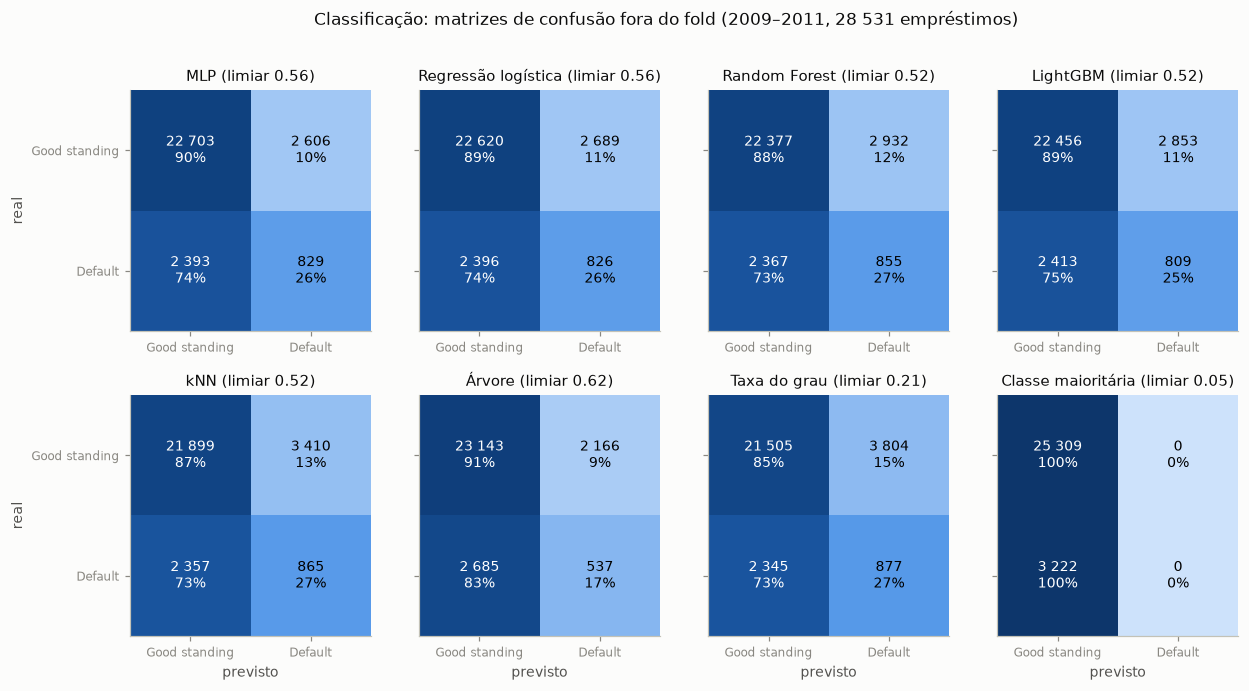

In [42]:
# Matrizes de confusão das previsões fora do fold (3 folds juntos), com o limiar de cada modelo
fig, axes = plt.subplots(2, 4, figsize=(13, 6.6))
for ax, model in zip(axes.flat, order):
    oof, threshold = chosen[model]["oof"], chosen[model]["threshold"]
    matrix = confusion_table(oof["y_true"], labels_from_proba(oof["p_default"], threshold))
    share = matrix.div(matrix.sum(axis=1), axis=0)
    ax.imshow(share.to_numpy(), cmap=SEQUENTIAL_CMAP, vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            count = f"{matrix.iloc[i, j]:,}".replace(",", " ")
            ax.text(j, i, f"{count}\n{share.iloc[i, j]:.0%}", ha="center", va="center",
                    color="white" if share.iloc[i, j] > 0.6 else "black")
    ax.set_xticks([0, 1], labels=["Good standing", "Default"])
    ax.set_yticks([0, 1], labels=["Good standing", "Default"])
    ax.grid(False)
    ax.set_title(f"{model} (limiar {threshold:.2f})")
for ax in axes[:, 0]:
    ax.set_ylabel("real")
for ax in axes[1, :]:
    ax.set_xlabel("previsto")
for ax in axes[:, 1:].flat:
    ax.set_yticklabels([])
fig.suptitle("Classificação: matrizes de confusão fora do fold (2009–2011, 28 531 empréstimos)")
fig.savefig(config.FIGURES_DIR / "mod_cls_confusao.png")
plt.show()

In [43]:
# Matriz de confusão de cada fold (TN, FP, FN, TP), com a precisão e o recall de Default
rows = []
for model in order:
    oof, threshold = chosen[model]["oof"], chosen[model]["threshold"]
    for fold, part in oof.groupby("fold"):
        matrix = confusion_table(part["y_true"], labels_from_proba(part["p_default"], threshold))
        tn, fp = matrix.loc["Good standing"]
        fn, tp = matrix.loc["Default"]
        rows.append({"modelo": model, "fold": fold, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
                     "Default reais (%)": 100 * (tp + fn) / len(part),
                     "Default previstos (%)": 100 * (tp + fp) / len(part),
                     "precision Default": tp / (tp + fp) if tp + fp else np.nan,
                     "recall Default": tp / (tp + fn)})
pd.DataFrame(rows).set_index(["modelo", "fold"]).round(3)

TN    FP    FN   TP  Default reais (%)  \
modelo              fold                                              
MLP                 1      3998   559   540  183             13.693   
                    2      7341   812   738  262             10.925   
                    3     11364  1235  1115  384             10.633   
Regressão logística 1      3944   613   536  187             13.693   
                    2      7259   894   720  280             10.925   
                    3     11417  1182  1140  359             10.633   
Random Forest       1      3537  1020   465  258             13.693   
                    2      7310   843   719  281             10.925   
                    3     11530  1069  1183  316             10.633   
LightGBM            1      3686   871   485  238             13.693   
                    2      7256   897   747  253             10.925   
                    3     11514  1085  1181  318             10.633   
kNN                 1      3838   719   539  184             13.693   
                    2      7134  1019   731  269             10.925   
                    3     10927  1672  1087  412             10.633   
Árvore              1      3791   766   511  212             13.693   
                    2      7536   617   850  150             10.925   
                    3     11816   783  1324  175             10.633   
Taxa do grau        1      2390  2167   257  466             13.693   
                    2      6779  1374   662  338             10.925   
                    3     12336   263  1426   73             10.633   
Classe maioritária  1      4557     0   723    0             13.693   
                    2      8153     0  1000    0             10.925   
                    3     12599     0  1499    0             10.633   

                          Default previstos (%)  precision Default  \
modelo              fold                                             
MLP                 1                    14.053              0.247   
                    2                    11.734              0.244   
                    3                    11.484              0.237   
Regressão logística 1                    15.152              0.234   
                    2                    12.826              0.239   
                    3                    10.931              0.233   
Random Forest       1                    24.205              0.202   
                    2                    12.280              0.250   
                    3                     9.824              0.228   
LightGBM            1                    21.004              0.215   
                    2                    12.564              0.220   
                    3                     9.952              0.227   
kNN                 1                    17.102              0.204   
                    2                    14.072              0.209   
                    3                    14.782              0.198   
Árvore              1                    18.523              0.217   
                    2                     8.380              0.196   
                    3                     6.795              0.183   
Taxa do grau        1                    49.867              0.177   
                    2                    18.704              0.197   
                    3                     2.383              0.217   
Classe maioritária  1                     0.000                NaN   
                    2                     0.000                NaN   
                    3                     0.000                NaN   

                          recall Default  
modelo              fold                  
MLP                 1              0.253  
                    2              0.262  
                    3              0.256  
Regressão logística 1              0.259  
                    2              0.280  
                    3              0.239  
Random Forest    

**As diferenças são reais?** O desvio entre folds mistura a variação dos dados de validação com a do treino, e assenta só em 3 valores. O *bootstrap* emparelhado mede diretamente a incerteza da diferença entre dois modelos:

1. reamostram-se com reposição as 28 531 previsões fora do fold, as mesmas linhas para os dois modelos;
2. em cada reamostragem, calcula-se a métrica como na tabela (em cada fold, e depois a média dos 3) para os dois modelos, e a diferença;
3. ao fim de 1 000 reamostragens, os percentis 2,5 e 97,5 das diferenças dão o intervalo de confiança a 95%.

Se o intervalo contém o 0, os dados não distinguem os dois modelos. Como as linhas são as mesmas, o que é comum aos dois modelos (empréstimos fáceis ou difíceis de prever) anula-se na diferença, e o intervalo fica mais estreito do que se se comparassem dois intervalos separados. A função é a `paired_bootstrap_diff` do `evaluation.py`. O *bootstrap* mede só a incerteza das previsões de validação: não volta a treinar os modelos.

A comparação faz-se entre o 1.º da tabela e cada um dos outros, e entre a regressão logística (a melhor AUC) e os modelos seguintes. Demora cerca de 5 minutos.

In [44]:
# Bootstrap emparelhado (1000 reamostragens) das previsões fora do fold
reference = chosen[order[0]]["oof"]
assert all((chosen[model]["oof"]["row"].to_numpy() == reference["row"].to_numpy()).all() for model in order)
y01 = reference["y_true"].eq("Default").to_numpy()
folds = reference["fold"].to_numpy()


def fold_mean_auc(y, score):
    """AUC média dos 3 folds. score: coluna 0 = probabilidade de Default, coluna 1 = fold."""
    return np.mean([roc_auc_score(y[score[:, 1] == k], score[score[:, 1] == k, 0]) for k in (1, 2, 3)])


def fold_mean_f1(y, score):
    """F1 macro médio dos 3 folds. score: coluna 0 = Default previsto (0/1) com o limiar, coluna 1 = fold."""
    values = []
    for k in (1, 2, 3):
        mask = score[:, 1] == k
        actual, predicted = y[mask].astype(bool), score[mask, 0].astype(bool)
        tp, fp, fn = (actual & predicted).sum(), (~actual & predicted).sum(), (actual & ~predicted).sum()
        tn = mask.sum() - tp - fp - fn
        values.append((2 * tp / (2 * tp + fp + fn) + 2 * tn / (2 * tn + fn + fp)) / 2)
    return np.mean(values)


scores = {}
for model in order:
    p = chosen[model]["oof"]["p_default"].to_numpy()
    scores[model] = {"F1 macro": np.column_stack([(p >= chosen[model]["threshold"]).astype(float), folds]),
                     "AUC": np.column_stack([p, folds])}
    # as duas funções dão exatamente os valores da tabela
    assert np.isclose(fold_mean_f1(y01, scores[model]["F1 macro"]), best.loc[model, "f1_macro_mean"])
    assert np.isclose(fold_mean_auc(y01, scores[model]["AUC"]), best.loc[model, "auc_mean"])

rows = []
for a, others in [(order[0], order[1:]), ("Regressão logística", ["Random Forest", "LightGBM", "kNN"])]:
    for b in others:
        row = {"modelo A": a, "modelo B": b}
        for name, metric in [("F1 macro", fold_mean_f1), ("AUC", fold_mean_auc)]:
            diff = paired_bootstrap_diff(metric, y01, scores[a][name], scores[b][name], n_boot=1000)
            row[f"{name}: A - B"] = diff["estimate"]
            row[f"{name}: IC 2,5%"] = diff["low"]
            row[f"{name}: IC 97,5%"] = diff["high"]
            row[f"{name}: diferença clara"] = "sim" if diff["low"] > 0 or diff["high"] < 0 else "não"
        rows.append(row)
boot = pd.DataFrame(rows)
boot.to_csv(runner.results_dir / "classification_bootstrap.csv", index=False)
boot.round(3)

,modelo A,modelo B,F1 macro: A - B,"F1 macro: IC 2,5%","F1 macro: IC 97,5%",F1 macro: diferença clara,AUC: A - B,"AUC: IC 2,5%","AUC: IC 97,5%",AUC: diferença clara
0,MLP,Regressão logística,0.003,-0.003,0.010,não,-0.003,-0.008,0.002,não
1,MLP,Random Forest,0.009,0.003,0.016,sim,0.003,-0.002,0.009,não
2,MLP,LightGBM,0.012,0.004,0.020,sim,0.022,0.013,0.030,sim
3,MLP,kNN,0.018,0.011,0.026,sim,0.024,0.017,0.031,sim
4,MLP,Árvore,0.032,0.023,0.041,sim,0.053,0.043,0.062,sim
5,MLP,Taxa do grau,0.061,0.052,0.069,sim,0.035,0.027,0.044,sim
6,MLP,Classe maioritária,0.104,0.096,0.112,sim,0.166,0.156,0.176,sim
7,Regressão logística,Random Forest,0.006,-0.001,0.013,não,0.006,0.001,0.012,sim
8,Regressão logística,LightGBM,0.009,0.001,0.017,sim,0.025,0.016,0.034,sim
9,Regressão logística,kNN,0.015,0.007,0.023,sim,0.027,0.019,0.035,sim


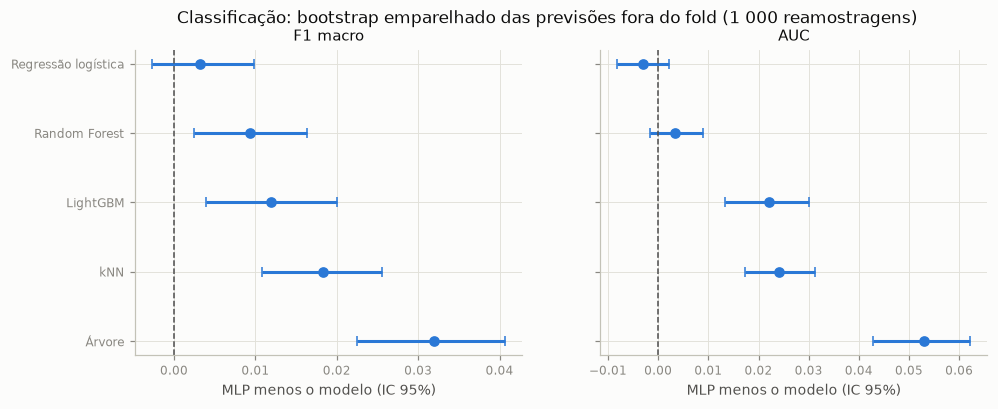

In [45]:
# Diferença entre o 1.º da tabela e cada modelo supervisionado, com o intervalo a 95%
part = boot[(boot["modelo A"] == order[0]) & ~boot["modelo B"].isin(["Taxa do grau", "Classe maioritária"])]
position = np.arange(len(part))[::-1]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, name in zip(axes, ["F1 macro", "AUC"]):
    estimate, low, high = part[f"{name}: A - B"], part[f"{name}: IC 2,5%"], part[f"{name}: IC 97,5%"]
    ax.errorbar(estimate, position, xerr=[estimate - low, high - estimate], fmt="o", capsize=3,
                color=CATEGORICAL[0])
    ax.axvline(0, color="0.3", linewidth=1, linestyle="--")
    ax.set(title=name, xlabel=f"{order[0]} menos o modelo (IC 95%)")
axes[0].set_yticks(position, labels=part["modelo B"])
fig.suptitle("Classificação: bootstrap emparelhado das previsões fora do fold (1 000 reamostragens)")
fig.savefig(config.FIGURES_DIR / "mod_cls_bootstrap.png")
plt.show()

**Leitura.**

*A tabela final*

- **Há um grupo da frente:** MLP (F1 macro 0,573, AUC 0,666), regressão logística (0,570; 0,669) e Random Forest (0,564; 0,662). Seguem-se o LightGBM e o kNN, e depois a árvore e as baselines.
- **Todos os modelos supervisionados passam a taxa do grau no F1 macro** (0,513). Na AUC, a árvore (0,613) fica abaixo do grau (0,630): uma árvore sozinha ordena pior do que a própria classificação da LendingClub.
- **A *accuracy* engana:** a mais alta é a da classe maioritária (0,882), que nunca prevê um *Default*. O F1 *micro* é igual à *accuracy* em todas as linhas, como explicado na secção 2.

*Limiar escolhido contra 0,5*

- **Nos modelos com pesos das classes, o limiar escolhido fica perto de 0,5** (0,52 a 0,62) e ganha pouco: entre 0,003 e 0,015 de F1 macro (MLP 0,563 → 0,573; logística 0,562 → 0,570; árvore 0,526 → 0,541). Com 0,5, estes modelos marcam mais empréstimos (a MLP marca 19–28%) e apanham mais *Default* (recall 0,39), mas com menos precisão. O limiar escolhido troca recall por precisão.
- **Sem pesos, o limiar é indispensável:** com 0,5, a taxa do grau não prevê nenhum *Default* e fica igual à classe maioritária (F1 macro 0,469).
- **O otimismo de escolher o limiar nas mesmas previsões é pequeno.** No fold 3, o limiar escolhido só com os folds 1 e 2 é o mesmo, ou difere em 0,01, e o F1 macro muda no máximo 0,002. No fold 2, o limiar vem só do fold 1 (5 280 previsões), varia mais (0,59 na MLP, 0,61 na logística) e custa até 0,010 de F1 macro nos modelos supervisionados (0,024 na taxa do grau). Para o teste, o limiar vem das 28 531 previsões dos 3 folds, por isso deve ser estável.

*Matrizes de confusão*

- **O que o melhor grupo consegue:** no fold 3 (empréstimos de 2011), a MLP marca 1 619 empréstimos, dos quais 384 entraram em *Default*: precisão de 0,24, contra uma taxa real de 10,6%, ou seja, 2,2 vezes a taxa base. Apanha 26% dos *Default* (384 de 1 499), marcando 11,5% dos empréstimos. A logística dá números quase iguais (precisão 0,23, recall 0,24).
- **Todos os modelos supervisionados ficam na mesma zona:** precisão de *Default* entre 0,18 e 0,25 e recall entre 0,12 e 0,36, conforme o fold. Com a informação disponível na concessão, a maioria dos *Default* parece-se com empréstimos bons. É o limite do problema, não de um modelo em particular.
- **A taxa do grau mostra outra vez a deriva:** o recall de *Default* cai de 0,65 no fold 1 para 0,05 no fold 3.

*As diferenças são reais?*

- **MLP e regressão logística são indistinguíveis:** a diferença no F1 macro é +0,003, com IC 95% [−0,003; 0,010], e na AUC −0,003 [−0,008; 0,002]. Os dois intervalos contêm o 0.
- **A Random Forest fica logo atrás:** perde para a MLP no F1 macro (+0,009 [0,003; 0,016]) e para a logística na AUC (+0,006 [0,001; 0,012]), e empata nas outras duas comparações.
- **A MLP e a logística são claramente melhores** do que o LightGBM, o kNN, a árvore e as baselines, nas duas métricas.

**Escolha do modelo (proposta).** A métrica principal é o F1 macro; quando o *bootstrap* não separa os primeiros em nenhuma das duas métricas, fica o modelo mais simples (parcimónia). A MLP e a logística não se separam, por isso propomos a **regressão logística (C = 0,1, limiar 0,56)** como modelo final da classificação:

- o mesmo desempenho: a melhor AUC e um F1 macro a 0,003 do primeiro;
- é interpretável: os *odds ratios* (passo 7) mostram porque é que um pedido é marcado, o que importa num modelo de crédito e na discussão de *fairness*;
- treina em 0,1 s contra 3,7 s, não precisa do TensorFlow para ser usada e é determinística.

A MLP fica como alternativa, e as duas devem ir ao teste de 2015 para confirmar o empate. A interpretação (passos 7 e 8) e o teste sem `issue_year` (passo 9) usam a regressão logística.

## 8. Interpretação: odds ratios da regressão logística

A regressão logística é o modelo final proposto (secção 7). Aqui é treinada em todo o treino (2007–2011, 31 522 empréstimos), com `C = 0,1`, tal como vai ao teste. Os seus coeficientes dizem que características do pedido aumentam ou diminuem o risco de *Default*, e quanto.

**Odds e odds ratio.** As *odds* de *Default* são $p / (1 - p)$: com $p = 0,2$, as *odds* são 0,25 (1 *Default* para 4 bons). A regressão logística modela o log das *odds* como uma soma: $\log \frac{p}{1-p} = \beta_0 + \beta_1 x_1 + \dots + \beta_m x_m$. O *odds ratio* de uma coluna é $e^{\beta}$: o fator por que as *odds* se multiplicam quando essa coluna sobe uma unidade e **todas as outras ficam iguais**. OR > 1 aumenta o risco; OR < 1 diminui-o; OR = 1 não tem efeito.

Como se leem aqui:

- **Por desvio-padrão:** o pipeline padroniza as colunas numéricas, por isso uma unidade é um desvio-padrão (DP). A coluna "1 DP" dá o DP em unidades originais. Nos montantes, que passam por um log, 1 DP é multiplicar o valor por um fator (por exemplo, "× 1,76" no rendimento).
- **O sinal:** o scikit-learn modela a classe `classes_[1]`, que é *Good standing*. O log-odds de *Default* é $-\beta$, e o OR de *Default* é $e^{-\beta}$.
- **Efeito condicional:** cada OR é o efeito de uma coluna com todas as outras fixas. Pode ser diferente da associação simples vista na EDA, que não controla nada. E é uma associação, não uma causa.
- **Colunas quase iguais** (correlação de 0,98 ou mais, como o FICO *low* e *high*): a penalização L2 reparte o efeito entre elas, às vezes com sinais opostos, e só a soma tem leitura. Estas colunas são juntas num grupo, e o efeito do grupo é a soma dos coeficientes, com o sinal da correlação.
- **Categorias:** o one-hot guarda todas as categorias, sem uma de referência. Por isso, cada categoria lê-se contra a mais frequente: $e^{-(\beta_\text{cat} - \beta_\text{ref})}$.
- **Grau, sub-grau e taxa de juro** dizem quase o mesmo, e leem-se juntos, como uma curva por sub-grau.
- **A L2 encolhe os coeficientes** em direção a 0, por isso os OR ficam um pouco mais perto de 1. Os pesos das classes mudam sobretudo o intercepto, não os declives.
- **Incerteza:** 200 reajustes do modelo em reamostragens *bootstrap* das linhas de treino (com o pré-processamento fixo) dão um intervalo de confiança a 95% para cada OR. Se o intervalo não contém o 1, o efeito é claro.

In [46]:
# Modelo final proposto, treinado em todo o treino (2007-2011)
final_logit = runner.refit(data, specs["Regressão logística"])
logit = final_logit.steps[-1][1]
A_all = final_logit[:-1].transform(ordered[runner.columns])
y_all = ordered[config.CLASS_COL]
# O scikit-learn modela classes_[1] = "Good standing": o log-odds de Default é -beta
beta = pd.Series(-logit.coef_[0], index=logit.feature_names_in_)
print(logit, "| classes:", list(logit.classes_), "| colunas:", A_all.shape[1])

pre = final_logit.named_steps["pre"]
onehot = list(pre.named_transformers_["categorical"].get_feature_names_out())
constant = [c for c in A_all.columns if A_all[c].std() == 0]
numeric = [c for c in A_all.columns if c not in onehot and c not in constant]
print(f"{len(numeric)} numéricas, {len(onehot)} do one-hot e {len(constant)} constantes nesta coorte:", constant)

# Desvio-padrão de cada coluna em unidades originais (o do StandardScaler, depois do log e do clipping)
scale = {name: (part, sd) for part in ["money", "numeric"]
         for name, sd in zip(pre.named_transformers_[part].named_steps["scale"].feature_names_in_,
                             pre.named_transformers_[part].named_steps["scale"].scale_)}

# Grupos de colunas quase iguais (|correlação| >= 0,98), ligadas em cadeia
corr = A_all[numeric].corr()
parent = {c: c for c in numeric}


def root(c):
    while parent[c] != c:
        c = parent[c]
    return c


for i, a in enumerate(numeric):
    for b in numeric[i + 1:]:
        if abs(corr.loc[a, b]) >= 0.98:
            parent[root(b)] = root(a)
groups = {}
for c in numeric:
    groups.setdefault(root(c), []).append(c)
sign = {lead: {c: np.sign(corr.loc[lead, c]) for c in members} for lead, members in groups.items()}
pd.Series({lead: ", ".join(members) for lead, members in groups.items() if len(members) > 1},
          name="colunas do grupo").rename_axis("grupo").to_frame()

LogisticRegression(C=0.1, class_weight='balanced', max_iter=2000) | classes: ['Default', 'Good standing'] | colunas: 112
50 numéricas, 56 do one-hot e 8 constantes nesta coorte: ['delinq_amnt', 'term', 'collections_12_mths_ex_med', 'acc_now_delinq', 'chargeoff_within_12_mths', 'tax_liens', 'initial_list_status_f', 'application_type_Individual']


,colunas do grupo
grupo,
loan_amnt,"loan_amnt, funded_amnt, installment"
missingindicator_annual_inc,"missingindicator_annual_inc, missingindicator_..."
missingindicator_delinq_amnt,"missingindicator_delinq_amnt, missingindicator..."
fico_range_low,"fico_range_low, fico_range_high"
pub_rec,"pub_rec, has_public_record, missingindicator_m..."
loan_to_income,"loan_to_income, installment_to_income"
ever_delinquent,"ever_delinquent, missingindicator_mths_since_l..."
missingindicator_collections_12_mths_ex_med,"missingindicator_collections_12_mths_ex_med, m..."


In [47]:
# Bootstrap: 200 reajustes da logística em reamostragens das linhas de treino (cerca de 1,5 minutos)
N_BOOT = 200
rng = np.random.default_rng(config.RANDOM_SEED)
boot_beta = np.empty((N_BOOT, A_all.shape[1]))
for b in range(N_BOOT):
    idx = rng.integers(0, len(A_all), len(A_all))
    boot_beta[b] = -clone(logit).fit(A_all.iloc[idx], y_all.iloc[idx]).coef_[0]
boot_beta = pd.DataFrame(boot_beta, columns=A_all.columns)


def interval(effect, effects_boot):
    """OR de Default, intervalo a 95% e se o intervalo exclui o 1."""
    low, high = np.percentile(effects_boot, [2.5, 97.5])
    return {"OR": np.exp(effect), "IC 2,5%": np.exp(low), "IC 97,5%": np.exp(high),
            "efeito claro": "sim" if low > 0 or high < 0 else "não"}

In [48]:
# Odds ratios das colunas numéricas (por 1 DP), com os grupos de colunas quase iguais juntos
GROUP_LABELS = {"fico_range_low": "FICO (low e high)",
                "loan_amnt": "montante (+ financiado + prestação)",
                "pub_rec": "registos públicos (3 colunas)",
                "loan_to_income": "montante / rendimento (+ prestação / rendimento)",
                "ever_delinquent": "já teve atraso (+ 1 coluna)"}


def label(lead, members):
    if lead in GROUP_LABELS:
        return GROUP_LABELS[lead]
    name = lead.replace("missingindicator_", "em falta: ")
    return f"{name} (+ {len(members) - 1} iguais)" if len(members) > 1 else name


def one_sd(column):
    part, sd = scale.get(column, (None, np.nan))
    if column.startswith("missingindicator_"):
        return "indicador 0/1"
    return f"× {np.exp(sd):.2f}" if part == "money" else f"{sd:.3g}"


rows = []
for lead, members in groups.items():
    effect = sum(sign[lead][c] * beta[c] for c in members)
    effect_boot = sum(sign[lead][c] * boot_beta[c] for c in members)
    rows.append({"variável": label(lead, members), "colunas": ", ".join(members), "1 DP": one_sd(lead),
                 "log-odds": effect, **interval(effect, effect_boot)})
odds_numeric = pd.DataFrame(rows)
odds_numeric = (odds_numeric.reindex(odds_numeric["log-odds"].abs().sort_values(ascending=False).index)
                .reset_index(drop=True))
odds_numeric.drop(columns="colunas").round(3)

,variável,1 DP,log-odds,OR,"IC 2,5%","IC 97,5%",efeito claro
0,int_rate,3.27,0.254,1.289,1.147,1.453,sim
1,inq_last_6mths,1.45,0.245,1.277,1.236,1.330,sim
2,FICO (low e high),36.6,-0.231,0.794,0.707,0.869,sim
3,registos públicos (3 colunas),0.228,0.201,1.223,1.092,1.354,sim
4,annual_inc,× 1.76,-0.176,0.839,0.771,0.904,sim
5,revol_util,28.5,0.145,1.156,1.095,1.214,sim
6,revol_to_income,0.2,0.137,1.147,1.085,1.196,sim
7,pub_rec_bankruptcies,0.2,-0.133,0.875,0.792,0.977,sim
8,revol_bal,× 7.20,-0.132,0.876,0.834,0.927,sim
9,em falta: tax_liens,indicador 0/1,-0.123,0.884,0.827,0.933,sim


In [49]:
# Categorias: OR de cada categoria contra a mais frequente da mesma variável
rows = []
for variable in ["purpose", "home_ownership", "verification_status"]:
    columns = [c for c in onehot if c.startswith(variable + "_")]
    share = A_all[columns].mean()
    reference = share.idxmax()
    for c in columns:
        if c != reference:
            effect = beta[c] - beta[reference]
            rows.append({"variável": variable, "categoria": c[len(variable) + 1:].replace("infrequent_sklearn", "outras (raras)"),
                         "referência": reference[len(variable) + 1:], "% do treino": 100 * share[c],
                         **interval(effect, boot_beta[c] - boot_beta[reference])})
odds_categories = pd.DataFrame(rows)
pd.concat([odds_numeric.assign(tipo="numérica (por 1 DP)"),
           odds_categories.assign(tipo="categoria (contra a referência)")]).to_csv(
    runner.results_dir / "classification_odds_ratios.csv", index=False)
odds_categories.round(3)

,variável,categoria,referência,% do treino,OR,"IC 2,5%","IC 97,5%",efeito claro
0,purpose,car,debt_consolidation,3.299,1.003,0.774,1.200,não
1,purpose,credit_card,debt_consolidation,13.933,0.736,0.636,0.839,sim
2,purpose,educational,debt_consolidation,1.285,1.324,1.013,1.680,sim
3,purpose,home_improvement,debt_consolidation,7.160,1.210,1.020,1.406,sim
4,purpose,house,debt_consolidation,0.945,0.984,0.695,1.411,não
5,purpose,major_purchase,debt_consolidation,5.793,0.895,0.742,1.075,não
6,purpose,medical,debt_consolidation,1.834,1.422,1.118,1.712,sim
7,purpose,moving,debt_consolidation,1.659,1.532,1.268,1.871,sim
8,purpose,other,debt_consolidation,11.173,1.295,1.149,1.443,sim
9,purpose,small_business,debt_consolidation,4.397,2.513,2.153,2.892,sim


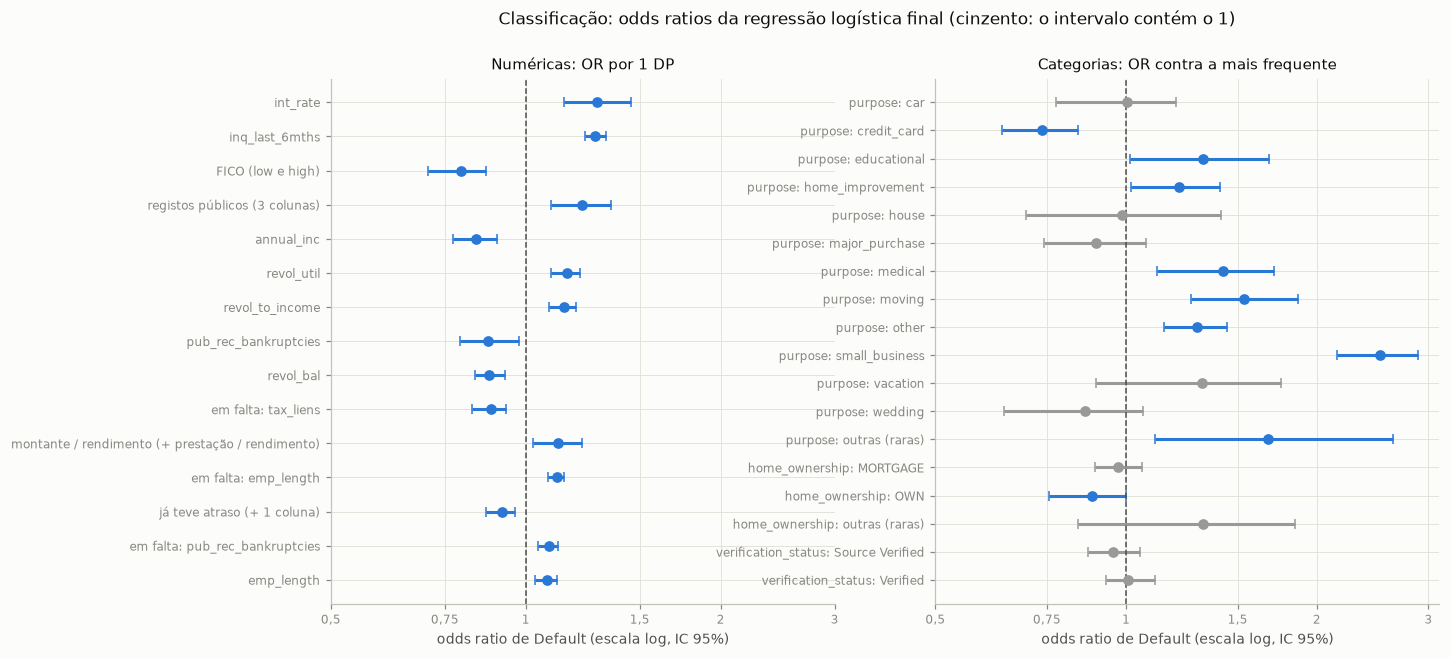

In [50]:
# Odds ratios de Default com o intervalo a 95%: as 15 numéricas de maior efeito e as categorias
top = odds_numeric.head(15).iloc[::-1]
cats = odds_categories.assign(nome=odds_categories["variável"] + ": " + odds_categories["categoria"]).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(13, 6.2))
for ax, frame, names, title in [(axes[0], top, top["variável"], "Numéricas: OR por 1 DP"),
                                (axes[1], cats, cats["nome"], "Categorias: OR contra a mais frequente")]:
    position = np.arange(len(frame))
    clear = frame["efeito claro"].eq("sim").to_numpy()
    for mask, color in [(clear, CATEGORICAL[0]), (~clear, "0.6")]:
        ax.errorbar(frame["OR"][mask], position[mask],
                    xerr=[(frame["OR"] - frame["IC 2,5%"])[mask], (frame["IC 97,5%"] - frame["OR"])[mask]],
                    fmt="o", capsize=3, color=color)
    ax.axvline(1, color="0.3", linewidth=1, linestyle="--")
    ax.set_xscale("log")
    ax.set_xticks([0.5, 0.75, 1, 1.5, 2, 3], labels=["0,5", "0,75", "1", "1,5", "2", "3"])
    ax.minorticks_off()
    ax.set_yticks(position, labels=names)
    ax.set(title=title, xlabel="odds ratio de Default (escala log, IC 95%)")
fig.suptitle("Classificação: odds ratios da regressão logística final (cinzento: o intervalo contém o 1)")
fig.savefig(config.FIGURES_DIR / "mod_cls_odds_ratios.png")
plt.show()

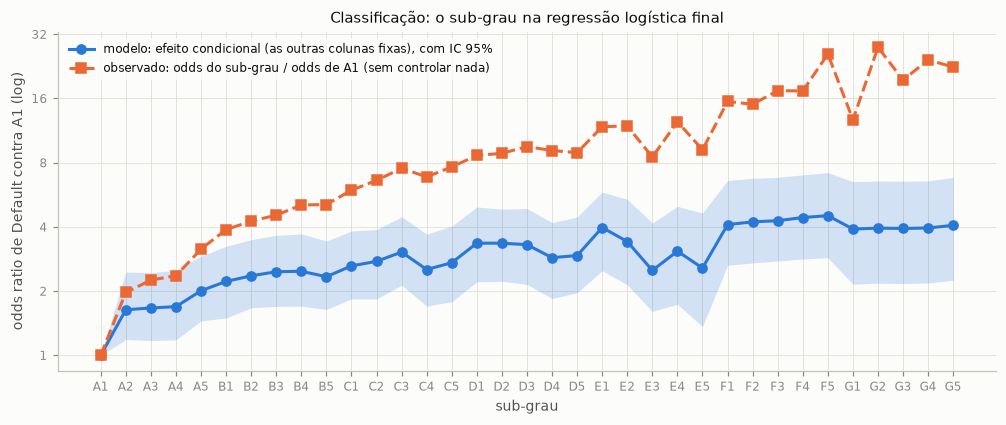

,empréstimos,taxa de Default,OR modelo,"IC 2,5%","IC 97,5%",OR observado
A1,1142,0.026,1.000,1.000,1.000,1.000
A2,1506,0.050,1.634,1.185,2.455,1.970
A3,1782,0.057,1.666,1.173,2.438,2.250
A4,2771,0.060,1.690,1.181,2.506,2.362
A5,2544,0.078,2.007,1.450,2.914,3.146
B1,1666,0.095,2.219,1.495,3.244,3.884
B2,1778,0.103,2.357,1.669,3.482,4.253
B3,2264,0.109,2.464,1.696,3.648,4.539
B4,1889,0.120,2.476,1.697,3.708,5.063
B5,2062,0.121,2.335,1.641,3.431,5.091


In [51]:
# Grau, sub-grau e taxa de juro juntos: OR de Default de cada sub-grau contra A1
# Modelo: média, nos empréstimos de cada sub-grau, da soma das colunas grade_*, sub_grade_* e int_rate
# (efeito condicional, com as outras colunas fixas). Observado: odds de Default do sub-grau / odds de A1.
grade_cols = [c for c in A_all.columns if c.startswith(("grade_", "sub_grade_"))] + ["int_rate"]
contribution = A_all[grade_cols].to_numpy() @ beta[grade_cols].to_numpy()
contribution_boot = A_all[grade_cols].to_numpy() @ boot_beta[grade_cols].to_numpy().T
sub_grade = ordered["sub_grade"].to_numpy()
levels = sorted(pd.unique(sub_grade))
mean = pd.Series({s: contribution[sub_grade == s].mean() for s in levels})
mean_boot = pd.DataFrame({s: contribution_boot[sub_grade == s].mean(axis=0) for s in levels})
band = np.exp(mean_boot.sub(mean_boot["A1"], axis=0)).quantile([0.025, 0.975])
rate = is_default.groupby(ordered["sub_grade"]).mean()
grade_odds = pd.DataFrame({"empréstimos": ordered["sub_grade"].value_counts().reindex(levels),
                           "taxa de Default": rate.reindex(levels),
                           "OR modelo": np.exp(mean - mean["A1"]),
                           "IC 2,5%": band.loc[0.025], "IC 97,5%": band.loc[0.975],
                           "OR observado": (rate / (1 - rate) / (rate["A1"] / (1 - rate["A1"]))).reindex(levels)})

fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(levels))
ax.fill_between(x, grade_odds["IC 2,5%"], grade_odds["IC 97,5%"], color=CATEGORICAL[0], alpha=0.2)
ax.plot(x, grade_odds["OR modelo"], marker="o", color=CATEGORICAL[0],
        label="modelo: efeito condicional (as outras colunas fixas), com IC 95%")
ax.plot(x, grade_odds["OR observado"], marker="s", linestyle="--", color=CATEGORICAL[1],
        label="observado: odds do sub-grau / odds de A1 (sem controlar nada)")
ax.set_yscale("log")
ax.set_yticks([1, 2, 4, 8, 16, 32], labels=["1", "2", "4", "8", "16", "32"])
ax.minorticks_off()
ax.set_xticks(x, labels=levels)
ax.set(xlabel="sub-grau", ylabel="odds ratio de Default contra A1 (log)",
       title="Classificação: o sub-grau na regressão logística final")
ax.legend(loc="upper left")
fig.savefig(config.FIGURES_DIR / "mod_cls_odds_subgrau.png")
plt.show()
grade_odds.round(3)

**Leitura.** Os OR são de *Default*, por 1 DP, com todas as outras colunas fixas.

*O que aumenta o risco*

- **Taxa de juro:** 1,29 [1,15; 1,45] por 3,3 p.p. Mesmo com o sub-grau fixo, uma taxa mais alta acompanha mais risco. A taxa leva informação de risco que a LendingClub juntou ao fixar o preço, e um empréstimo mais caro também pesa mais no orçamento.
- **Pedidos de crédito nos últimos 6 meses:** 1,28 [1,24; 1,33] por 1,5 pedidos. É o efeito mais bem estimado (o intervalo mais estreito): quem anda à procura de crédito está mais apertado.
- **Registos públicos:** 1,22 [1,09; 1,35]. São 3 colunas iguais: `pub_rec`, `has_public_record` e o indicador de falta da data do último registo. A `pub_rec_bankruptcies`, com correlação de 0,87 com estas, vai no sentido oposto (0,88 [0,79; 0,98]). Entre os registos públicos, uma falência pesa menos do que os outros (penhoras, sentenças).
- **O peso da dívida em relação ao rendimento:**
    - utilização do crédito rotativo: 1,16 por 28,5 p.p.;
    - saldo rotativo / rendimento: 1,15 por 0,2;
    - montante / rendimento: 1,12 por 0,1 do rendimento anual.
- **Finalidade:** *small business* tem 2,5 vezes as *odds* de *debt consolidation* [2,15; 2,89], o maior efeito do modelo. Também aumentam o risco *moving* (1,53), *medical* (1,42), *educational* (1,32), *other* (1,30) e *home improvement* (1,21).

*O que diminui o risco*

- **FICO:** 0,79 [0,71; 0,87] por 37 pontos. As colunas *low* e *high* são iguais (correlação 1,00), e a L2 dividiu o efeito ao meio. Lida sozinha, cada uma teria um OR de 0,89, que subestima o efeito.
- **Rendimento:** 0,84 [0,77; 0,90] por cada vez que o rendimento é multiplicado por 1,76.
- **Finalidade *credit card*:** 0,74 [0,64; 0,84] contra *debt consolidation*.
- **Ano de emissão:** 0,95 [0,90; 0,99] por ano. Com as mesmas características, os empréstimos mais recentes entram menos em *Default*. Reflete a mudança do contexto económico depois de 2008–2009, e é o que o passo 9 vai testar, ao tirar o `issue_year`.

*O que não conta, dado o resto*

- **DTI:** 1,01 [0,97; 1,05]. Na EDA da Parte 1, a taxa de *Default* subia de cerca de 11% para 14% com o DTI, mas isso era a associação simples. Com o montante / rendimento, o crédito rotativo, o FICO e a taxa no modelo, o DTI não acrescenta nada: a sua informação já está nas outras colunas.
- **Montante do empréstimo** (com o montante financiado e a prestação): 0,97 [0,89; 1,07]. O montante em si não importa; importa o montante em relação ao rendimento.
- **Verificação do rendimento** (0,95 e 1,01) e **casa hipotecada** contra arrendada (0,97) não têm efeito. Só a casa própria fica no limite (0,88 [0,76; 1,00]).

*Sinais inesperados*

- **O saldo rotativo diminui o risco (0,88) e o saldo / rendimento aumenta-o (1,15).** O log do saldo é quase o log do rácio mais o log do rendimento. Com o rácio e o rendimento fixos, o saldo quase não pode variar, por isso os dois coeficientes compensam-se e não se leem separadamente.
- **Os anos de emprego aumentam ligeiramente o risco:** 1,08 [1,03; 1,12] por 3,5 anos, o contrário do esperado. É um efeito pequeno, condicional ao resto, numa variável truncada em "10+ anos", e não deve ser lido como causa. A falta dos anos de emprego (quem não os declara) aumenta o risco: 1,12.

*O sub-grau*

- **A curva do modelo sobe com o sub-grau:** de 1 (A1) para cerca de 2 em A5, 3 em D e 4 em F e G. A curva observada sobe muito mais: 3 em A5, 9 em D e 13 a 28 em F e G.
- **A diferença é a informação que o modelo já tem por outras vias.** O grau da LendingClub resume o FICO, os pedidos de crédito, o rendimento e outras características do pedido. Com essas colunas no modelo, sobra para o sub-grau e para a taxa só a parte do risco que elas não explicam.
- **A curva do modelo não é sempre crescente** (C4, E3, E5), e os intervalos são largos. Os coeficientes de cada sub-grau são ruidosos e a L2 reparte o efeito com o grau e a taxa. Os F e os G são raros (menos de 0,5% cada) e ficam juntos numa categoria, por isso, dentro deles, só a taxa de juro faz variar a curva.

*Limites*

- Os OR são do modelo treinado em 2007–2011 e descrevem associações condicionais, não causas.
- A L2 encolhe os coeficientes, por isso os efeitos reais podem ser um pouco maiores.
- Os intervalos do *bootstrap* mantêm o pré-processamento fixo e ignoram a ordem temporal: medem a incerteza da amostra, não a mudança ao longo do tempo.
- **Fairness:** o modelo não usa atributos protegidos, mas a finalidade e a situação da casa podem funcionar como *proxies* de características socioeconómicas. Isso fica para a discussão de *fairness* no teste de 2015.

## 9. Importância por permutação e dependência parcial

Os *odds ratios* só existem na regressão logística. As duas técnicas desta secção servem para qualquer modelo, por isso comparam a logística com a MLP e a Random Forest, os três primeiros da tabela.

**Importância por permutação.** Baralha-se uma coluna nos dados de validação e mede-se quanto cai a AUC. Baralhar corta a ligação entre a coluna e o desfecho, mas mantém a sua distribuição. Se o modelo depende da coluna, a AUC cai; se a ignora, não muda.

- **Fora do fold:** em cada fold, o modelo é treinado no passado e a importância é medida na validação (2009, 2010 e 2011). Medida no treino, a importância incluiria o que o modelo decorou.
- **Colunas originais:** baralham-se as colunas que entram no pipeline, antes das features derivadas, por isso cada coluna leva consigo o que se calcula a partir dela. Por exemplo, baralhar o `annual_inc` também baralha o montante / rendimento.
- **Grupos:** colunas que dizem o mesmo baralham-se juntas (FICO *low* e *high*; grau e sub-grau; montante, financiado e prestação). Baralhada sozinha, cada uma parecia pouco importante, porque a outra ainda tinha a informação.
- **Colunas ligadas por uma regra também se baralham juntas.** O `open_acc_pct` é `open_acc / total_acc` e só existe se as contas abertas não passarem do total. Baralhar só uma das duas cria combinações impossíveis, e o modelo reage a dados absurdos, não à falta de informação. A célula seguinte mostra esta armadilha, que é uma limitação conhecida da importância por permutação.
- **Limite:** com colunas correlacionadas mas diferentes (por exemplo, a taxa e o grau), a importância de cada uma é a parte que as outras não substituem.
- 3 repetições por coluna e fold; o resultado é a média ± desvio entre os 3 folds. Demora cerca de 5 minutos.

**Dependência parcial (PDP).** Para cada valor $v$ de uma coluna, põe-se essa coluna igual a $v$ em todos os empréstimos de uma amostra e faz-se a média das probabilidades previstas. A curva mostra como a previsão muda com a coluna, em média, com as outras como estão. Aqui faz-se para o FICO (o *low* e o *high* juntos, com 4 pontos de diferença) e para a taxa de juro, com os três modelos treinados em todo o treino.

- **Escala real:** com os pesos *balanced*, as probabilidades ficam deslocadas para cima. Para as comparar com a taxa de *Default* observada, desfaz-se o efeito dos pesos com a correção da *prior*: odds reais = odds previstas × $\pi / (1 - \pi)$, com $\pi$ a taxa de *Default* do treino (12,3%). É uma aproximação, verificada abaixo.
- **Limite:** ao mudar só o FICO, a PDP cria combinações raras na realidade (FICO baixo com grau A e taxa baixa). Mostra o efeito do FICO para além do que a taxa e o grau já dizem, como os *odds ratios*.

In [52]:
# Armadilha: baralhar o open_acc sem o total_acc (fold 3, regressão logística)
tr, va = list(runner.splitter.split(ordered["issue_d"]))[2]
pipe = runner.refit(ordered.iloc[tr], specs["Regressão logística"])
X_va, y_va = ordered[runner.columns].iloc[va], is_default.iloc[va].to_numpy()
shuffled = X_va.copy()
shuffled["open_acc"] = X_va["open_acc"].to_numpy()[np.random.default_rng(config.RANDOM_SEED).permutation(len(X_va))]
A_va, A_shuffled = pipe[:-1].transform(X_va), pipe[:-1].transform(shuffled)
print(f"Mais contas abertas do que no total, depois de baralhar: "
      f"{(shuffled['open_acc'] > shuffled['total_acc']).mean():.1%} dos empréstimos (antes: "
      f"{(X_va['open_acc'] > X_va['total_acc']).mean():.1%})")
print(f"Indicador de falta do open_acc_pct, padronizado (máximo): "
      f"{A_va['missingindicator_open_acc_pct'].max():.2f} -> {A_shuffled['missingindicator_open_acc_pct'].max():.2f}")
print(f"AUC da logística: {roc_auc_score(y_va, positive_proba(pipe, X_va)):.3f} -> "
      f"{roc_auc_score(y_va, positive_proba(pipe, shuffled)):.3f}")

Mais contas abertas do que no total, depois de baralhar: 12.0% dos empréstimos (antes: 0.0%)
Indicador de falta do open_acc_pct, padronizado (máximo): -0.04 -> 23.69


AUC da logística: 0.676 -> 0.628


In [53]:
# Importância por permutação, fora do fold, nas colunas originais com informação nesta coorte
raw = [c for c in runner.columns if ordered[c].nunique(dropna=False) > 1]
RAW_GROUPS = {"FICO (low e high)": ["fico_range_low", "fico_range_high"],
              "grau e sub-grau": ["grade", "sub_grade"],
              "montante, financiado e prestação": ["loan_amnt", "funded_amnt", "installment"],
              "contas abertas e total (open_acc, total_acc)": ["open_acc", "total_acc"]}
in_groups = {c for columns in RAW_GROUPS.values() for c in columns}
perm_groups = {**RAW_GROUPS, **{c: [c] for c in raw if c not in in_groups}}
print(f"{len(raw)} colunas originais com informação ({len(runner.columns) - len(raw)} vazias ou constantes); "
      f"{len(perm_groups)} grupos a baralhar")

PERM_MODELS = ["Regressão logística", "MLP", "Random Forest"]
N_REPEATS = 3
rng = np.random.default_rng(config.RANDOM_SEED)
rows = []
for fold, (tr, va) in enumerate(runner.splitter.split(ordered["issue_d"]), start=1):
    X_va, y_va = ordered[runner.columns].iloc[va], is_default.iloc[va].to_numpy()
    for name in PERM_MODELS:
        pipe = runner.refit(ordered.iloc[tr], specs[name])    # a configuração escolhida, só com o passado
        base = roc_auc_score(y_va, positive_proba(pipe, X_va))
        for group, columns in perm_groups.items():
            drops = []
            for _ in range(N_REPEATS):
                shuffled, order_ = X_va.copy(), rng.permutation(len(X_va))
                for c in columns:
                    shuffled[c] = X_va[c].to_numpy()[order_]
                drops.append(base - roc_auc_score(y_va, positive_proba(pipe, shuffled)))
            rows.append({"fold": fold, "modelo": name, "variável": group, "AUC": base,
                         "queda da AUC": np.mean(drops)})
importance = pd.DataFrame(rows)
importance.to_csv(runner.results_dir / "classification_permutation_importance.csv", index=False)

# AUC de cada modelo em cada fold (igual à do runner)
importance.drop_duplicates(["fold", "modelo"]).pivot(index="modelo", columns="fold", values="AUC").round(3)

31 colunas originais com informação (69 vazias ou constantes); 26 grupos a baralhar


fold,1,2,3
modelo,,,
MLP,0.637,0.678,0.682
Random Forest,0.622,0.691,0.674
Regressão logística,0.645,0.685,0.676


In [54]:
# Queda da AUC (média ± desvio nos 3 folds), ordenada pela logística
summary_imp = importance.groupby(["variável", "modelo"])["queda da AUC"].agg(["mean", "std"]).unstack("modelo")
summary_imp = summary_imp.sort_values(("mean", "Regressão logística"), ascending=False)
pd.DataFrame({name: [format_mean_std(m, s) for m, s in zip(summary_imp[("mean", name)], summary_imp[("std", name)])]
              for name in PERM_MODELS}, index=summary_imp.index).head(20)

,Regressão logística,MLP,Random Forest
variável,,,
annual_inc,0.034 ± 0.013,0.033 ± 0.017,0.029 ± 0.020
FICO (low e high),0.023 ± 0.009,0.023 ± 0.008,0.011 ± 0.002
purpose,0.022 ± 0.003,0.016 ± 0.007,0.004 ± 0.003
inq_last_6mths,0.015 ± 0.010,0.016 ± 0.011,0.017 ± 0.012
grau e sub-grau,0.011 ± 0.010,0.002 ± 0.003,0.002 ± 0.002
int_rate,0.010 ± 0.011,0.013 ± 0.007,0.018 ± 0.011
pub_rec,0.005 ± 0.006,0.002 ± 0.003,0.000 ± 0.000
emp_length,0.003 ± 0.005,0.002 ± 0.004,0.000 ± 0.001
mths_since_last_delinq,0.003 ± 0.003,0.002 ± 0.001,0.000 ± 0.001


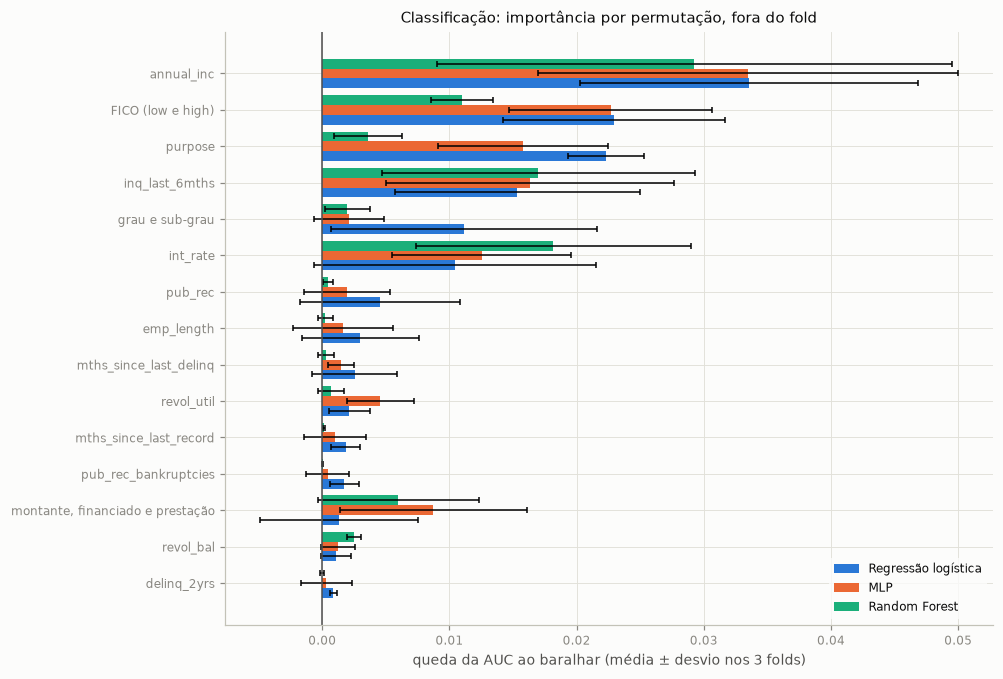

In [55]:
# Figura: as 15 colunas mais importantes para a logística, nos três modelos
top = summary_imp.head(15).iloc[::-1]
position = np.arange(len(top))
height = 0.27
fig, ax = plt.subplots(figsize=(9, 7))
for k, (name, color) in enumerate(zip(PERM_MODELS, CATEGORICAL)):
    ax.barh(position + (k - 1) * height, top[("mean", name)], height=height, xerr=top[("std", name)],
            color=color, label=name, error_kw={"elinewidth": 1, "capsize": 2})
ax.axvline(0, color="0.3", linewidth=1)
ax.set_yticks(position, labels=top.index)
ax.set(xlabel="queda da AUC ao baralhar (média ± desvio nos 3 folds)",
       title="Classificação: importância por permutação, fora do fold")
ax.legend(loc="lower right")
fig.savefig(config.FIGURES_DIR / "mod_cls_importancia.png")
plt.show()

Taxa de Default do treino: 0.123
  Regressão logística: média prevista 0.451, corrigida 0.123


  MLP: média prevista 0.442, corrigida 0.124
  Random Forest: média prevista 0.401, corrigida 0.097


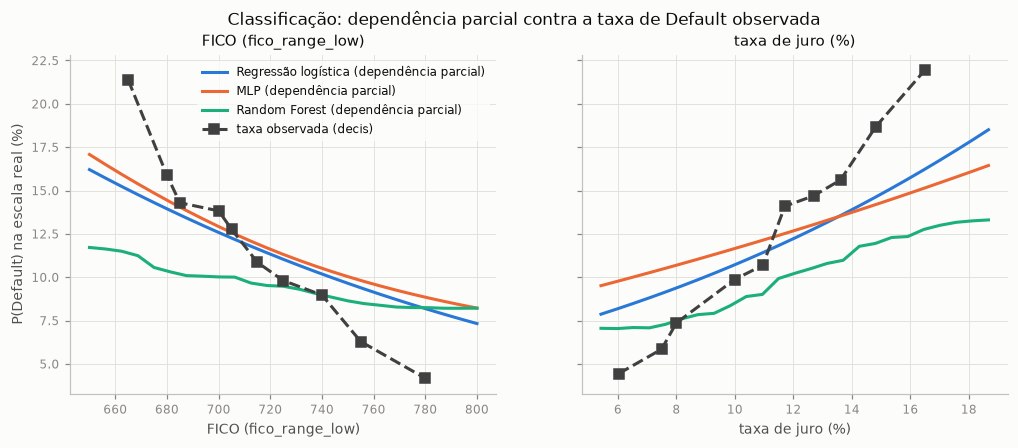

valor_min  P_min  valor_max  P_max
variável              modelo                                                 
FICO (fico_range_low) MLP                     650.00  0.171     800.00  0.082
                      Random Forest           650.00  0.117     800.00  0.082
                      Regressão logística     650.00  0.162     800.00  0.073
taxa de juro (%)      MLP                       5.42  0.095      18.67  0.164
                      Random Forest             5.42  0.071      18.67  0.133
                      Regressão logística       5.42  0.079      18.67  0.185

In [56]:
# Dependência parcial do FICO e da taxa de juro, com os modelos treinados em todo o treino
final_models = {"Regressão logística": final_logit,
                "MLP": runner.refit(data, specs["MLP"]),
                "Random Forest": runner.refit(data, specs["Random Forest"])}
X_sample = ordered[runner.columns].sample(5000, random_state=config.RANDOM_SEED)
base_rate = is_default.mean()


def real_scale(p):
    """Desfaz os pesos balanced (correção da prior): odds reais = odds previstas x taxa / (1 - taxa)."""
    odds = p / (1 - p) * base_rate / (1 - base_rate)
    return odds / (1 + odds)


# Verificação da correção: a média das probabilidades corrigidas deve ficar perto da taxa real
print(f"Taxa de Default do treino: {base_rate:.3f}")
for name, pipe in final_models.items():
    p = positive_proba(pipe, X_sample)
    print(f"  {name}: média prevista {p.mean():.3f}, corrigida {real_scale(p).mean():.3f}")

PDP_COLUMNS = {"FICO (fico_range_low)": lambda X, v: X.assign(fico_range_low=v, fico_range_high=v + 4),
               "taxa de juro (%)": lambda X, v: X.assign(int_rate=v)}
source = {"FICO (fico_range_low)": "fico_range_low", "taxa de juro (%)": "int_rate"}
pdp = []
for feature, setter in PDP_COLUMNS.items():
    grid = np.linspace(*ordered[source[feature]].quantile([0.01, 0.99]), 25)
    for name, pipe in final_models.items():
        for v in grid:
            pdp.append({"variável": feature, "modelo": name, "valor": v,
                        "P(Default)": real_scale(positive_proba(pipe, setter(X_sample, v))).mean()})
pdp = pd.DataFrame(pdp)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, feature in zip(axes, PDP_COLUMNS):
    for name, color in zip(PERM_MODELS, CATEGORICAL):
        part = pdp[(pdp["variável"] == feature) & (pdp["modelo"] == name)]
        ax.plot(part["valor"], 100 * part["P(Default)"], color=color, label=f"{name} (dependência parcial)")
    column = ordered[source[feature]]
    bins = pd.qcut(column, 10, duplicates="drop")
    observed = is_default.groupby(bins, observed=True).mean()
    centers = column.groupby(bins, observed=True).median()
    ax.plot(centers, 100 * observed, "s--", color="0.25", label="taxa observada (decis)")
    ax.set(xlabel=feature, title=feature)
axes[0].set_ylabel("P(Default) na escala real (%)")
axes[0].legend(loc="upper right")
fig.suptitle("Classificação: dependência parcial contra a taxa de Default observada")
fig.savefig(config.FIGURES_DIR / "mod_cls_pdp.png")
plt.show()

# Valores nos extremos da grelha (percentis 1 e 99)
(pdp.groupby(["variável", "modelo"])
 .agg(valor_min=("valor", "first"), P_min=("P(Default)", "first"), valor_max=("valor", "last"), P_max=("P(Default)", "last"))
 .round(3))

**Leitura.**

*A armadilha*

- **Baralhar só o `open_acc` cria 12% de empréstimos impossíveis,** com mais contas abertas do que no total. O pipeline marca-os como em falta, e o indicador de falta quase nunca vale 1 no treino. Depois de padronizado, passa de −0,04 para 23,7, e a AUC da logística cai de 0,676 para 0,628.
- **Seria uma "importância" falsa:** mede a reação do modelo a dados absurdos, não a dependência da informação. Baralhando as duas colunas juntas, a queda é 0,000–0,001.
- **É uma limitação geral da importância por permutação:** quando as colunas estão ligadas, baralhar uma avalia o modelo fora da zona dos dados reais.

*O que os modelos usam* (queda da AUC, média dos 3 folds)

- **Os três modelos usam a mesma informação principal:**
    - o rendimento (0,029–0,034), que inclui o montante / rendimento, a prestação / rendimento e o saldo / rendimento;
    - o FICO (0,011–0,023);
    - os pedidos de crédito nos últimos 6 meses (0,015–0,017);
    - a taxa de juro (0,010–0,018).
- **A finalidade conta para a logística e para a MLP** (0,022 e 0,016), mas pouco para a Random Forest (0,004). Com folhas de pelo menos 50 empréstimos, as árvores raramente separam pelas finalidades raras, como *small business* (4% do treino).
- **O grau e o sub-grau só contam para a logística** (0,011, contra 0,002 nos outros dois). A MLP e a Random Forest vão buscar a mesma informação à taxa de juro, que é fixada a partir do sub-grau. Quando duas colunas se substituem, a permutação de uma subestima a sua importância, porque a outra compensa.
- **O DTI, a verificação do rendimento e a situação da casa ficam perto de 0** nos três modelos, o que bate com os *odds ratios* do passo 7.
- **O `issue_d` tem importância 0 por construção:** cada fold de validação é um só ano, por isso baralhar a data não muda o ano. O efeito do ano mede-se tirando-o do modelo (passo 9).
- **Os desvios entre folds são grandes** (por exemplo, rendimento 0,034 ± 0,013): o fold 1 só tem 2 991 empréstimos de treino. A ordem das colunas principais é a mesma; os valores exatos não são precisos.

*Dependência parcial* (escala real, entre os percentis 1 e 99)

- **FICO de 650 para 800:** a probabilidade de *Default* desce de 16,2% para 7,3% na logística e de 17,1% para 8,2% na MLP. A taxa observada desce mais, de cerca de 21% para 4%. Como nos *odds ratios*, o efeito condicional (com a taxa e o grau fixos) é cerca de metade do observado: parte da informação do FICO já está na taxa e no grau.
- **Taxa de juro de 5,4% para 18,7%:** a probabilidade sobe de 7,9% para 18,5% na logística e de 9,5% para 16,4% na MLP. A observada sobe de cerca de 4% para 22%.
- **A MLP desenha quase as mesmas curvas que a logística,** suaves e quase lineares. Não encontrou nenhuma forma não linear que a logística não tenha, o que explica o empate da secção 7.
- **A Random Forest dá curvas mais planas e em degraus.** As árvores dividem a variável em intervalos, e as probabilidades da RF são menos calibradas: a média corrigida fica em 9,7%, contra 12,3%. Na RF, só a forma das curvas é comparável.